### google drive

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


### import

In [2]:
import pandas as pd
import numpy as np

# 1. Business Understanding


## 1.1 Increase Basket Size

> ธุรกิจต้องการเพิ่มจำนวนสินค้าและมูลค่าการซื้อต่อหนึ่งธุรกรรม
โดยวิเคราะห์ว่าสินค้าใดมีแนวโน้มถูกซื้อร่วมกัน เพื่อนำผลที่ได้ไปใช้ในการ
ออกแบบโปรโมชันแบบ Bundle, Cross-selling และการจัดวางสินค้า

## Business Question

> สินค้าใดมักถูกซื้อร่วมกัน และคู่หรือกลุ่มสินค้าใดเหมาะสำหรับนำมาจัด
โปรโมชันร่วมกันเพื่อเพิ่ม Basket Size?

## Analytical Approach

> ใช้ Market Basket Analysis ด้วย Association Rule Mining โดยเปรียบเทียบ
2 Algorithms

- Apriori
- FP-Growth

ทั้งสองวิธีจะใช้เกณฑ์เดียวกันในการสร้าง Frequent Itemsets และ
Association Rules เพื่อให้สามารถเปรียบเทียบผลได้อย่างยุติธรรม

## Evaluation Metrics

> Association Rules จะประเมินด้วย

- Support: ความถี่ที่ชุดสินค้าปรากฏร่วมกันในธุรกรรมทั้งหมด
- Confidence: ความน่าจะเป็นที่จะซื้อสินค้า B เมื่อซื้อสินค้า A
- Lift: ความสัมพันธ์ของการซื้อสินค้าร่วมกันเมื่อเทียบกับการเกิดโดยอิสระ

นอกจากนี้จะเปรียบเทียบประสิทธิภาพของ Apriori และ FP-Growth
ด้วย Execution Time และจำนวน Frequent Itemsets ที่ค้นพบ


## 1.2 Customer Segmentation

> ธุรกิจต้องการทำความเข้าใจความแตกต่างของพฤติกรรมการซื้อของลูกค้า
เพื่อแบ่งลูกค้าออกเป็นกลุ่มที่มีลักษณะคล้ายคลึงกัน และนำไปใช้ในการ
วางแผนการตลาด การออกแบบโปรโมชัน และการดูแลลูกค้าแต่ละกลุ่ม
ได้อย่างเหมาะสม

## Business Question

> พฤติกรรมการซื้อสามารถแบ่งลูกค้าออกเป็นกี่กลุ่ม และลูกค้าแต่ละกลุ่ม
มีลักษณะเด่นแตกต่างกันอย่างไร?

## Analytical Approach

> ใช้ Customer Segmentation โดยสร้างตัวแปร RFM ได้แก่

- Recency (R): ระยะเวลาตั้งแต่การซื้อครั้งล่าสุด
- Frequency (F): จำนวนครั้งที่ลูกค้าซื้อสินค้า
- Monetary (M): ยอดใช้จ่ายรวมของลูกค้า

จากนั้นใช้ K-Means Clustering เพื่อจัดกลุ่มลูกค้าที่มีพฤติกรรม
การซื้อคล้ายคลึงกัน โดยทำ Log Transformation และ Standardization
กับตัวแปรที่มีการกระจายแบบเบ้ก่อนนำเข้าสู่โมเดล

*** จำนวน Cluster ที่เหมาะสมจะพิจารณาจาก Elbow Method และ
Silhouette Score ร่วมกับความสามารถในการตีความแต่ละกลุ่ม
ในเชิงธุรกิจ

## Evaluation Metrics

> ประเมินผลการแบ่งกลุ่มด้วย

- Elbow Method: พิจารณาการลดลงของ Within-Cluster Sum of Squares (WCSS)
- Silhouette Score: วัดความคล้ายกันภายในกลุ่มและความแตกต่างระหว่างกลุ่ม
- Cluster Profile: วิเคราะห์ค่า RFM และพฤติกรรมเด่นของลูกค้าในแต่ละกลุ่ม

ผลลัพธ์จะถูกนำมาใช้กำหนด Customer Profile และกลยุทธ์ที่เหมาะสม
สำหรับลูกค้าแต่ละกลุ่ม


## 1.3 Customer Retention

> ธุรกิจต้องการระบุลูกค้าที่มีแนวโน้มจะหยุดซื้อสินค้า (Churn)
ล่วงหน้า เพื่อให้สามารถดำเนินมาตรการรักษาลูกค้าได้ก่อนที่จะสูญเสีย
ลูกค้าไป รวมถึงค้นหาพฤติกรรมที่เป็นสัญญาณเตือนของการ Churn

## Business Question

> ลูกค้ารายใดมีแนวโน้มจะหยุดซื้อ และพฤติกรรมใดเป็นสัญญาณเตือน
ที่สัมพันธ์กับการ Churn?

## Churn Definition

> กำหนดให้ลูกค้าเป็น Churn เมื่อไม่มีการซื้อสินค้าเป็นเวลามากกว่า
90 วัน ณ วันที่อ้างอิง 31 สิงหาคม 2026 เพื่อป้องกัน Data Leakage จะแบ่งข้อมูลออกเป็น 2 ช่วง

- Feature Window: 1 กันยายน 2024 – 1 มิถุนายน 2026
  ใช้สำหรับสร้างตัวแปรที่ใช้ทำนายทั้งหมด

- Outcome Window: 2 มิถุนายน 2026 – 31 สิงหาคม 2026
  ใช้สำหรับกำหนดสถานะ Churn เท่านั้น และไม่นำข้อมูลในช่วงนี้
  มาใช้เป็น Feature

ดังนั้น `recency_days` และ `last_purchase_date` จาก
`churn_labels.csv` จะไม่นำมาใช้เป็น Feature เนื่องจากเป็นข้อมูล
ที่เกี่ยวข้องโดยตรงกับการสร้าง Target

## Analytical Approach

> ใช้ Supervised Machine Learning สำหรับ Binary Classification
โดยกำหนด

- Target = `churn`
- 1 = Churned
- 0 = Active

> สร้าง Features จากพฤติกรรมของลูกค้าใน Feature Window เช่น

- Recency ณ วันที่ 1 มิถุนายน 2026
- จำนวนครั้งที่ซื้อในช่วง 30, 90, 180 และ 365 วัน
- ยอดใช้จ่ายและมูลค่าต่อ Basket
- แนวโน้มความถี่และยอดซื้อที่เพิ่มขึ้นหรือลดลง
- การพึ่งพาส่วนลด
- ความหลากหลายของ Category และ Channel
- จำนวน Support Tickets และ Satisfaction Score
- ข้อมูลพื้นฐานของลูกค้า

จากนั้นสร้าง Classification Model เพื่อประมาณความน่าจะเป็น
ที่ลูกค้าแต่ละรายจะ Churn

## Evaluation Metrics

> เนื่องจากข้อมูลมีสัดส่วนลูกค้า Churn ประมาณ 24.8%
จึงไม่ใช้ Accuracy เป็นตัวชี้วัดเพียงอย่างเดียว แต่พิจารณา

- Recall: ความสามารถในการตรวจพบลูกค้าที่ Churn จริง
- Precision: ความถูกต้องของลูกค้าที่โมเดลระบุว่าเสี่ยง Churn
- F1-Score: สมดุลระหว่าง Precision และ Recall
- ROC-AUC: ความสามารถโดยรวมในการแยก Churn และ Active
- PR-AUC: ประสิทธิภาพของโมเดลเมื่อข้อมูล Target ไม่สมดุล

นอกจากนี้จะวิเคราะห์ Feature Importance หรือ Model Coefficients
เพื่อค้นหาพฤติกรรมที่เป็นสัญญาณเตือนสำคัญของการ Churn
และนำไปพัฒนากลยุทธ์ Customer Retention


# 2. Data Understanding

## 2.1 Dataset Overview
ชุดข้อมูลที่ใช้ในโครงการประกอบด้วยข้อมูลหลัก 6 ตาราง ได้แก่ Customers, Products, Transactions, Transaction Items, Support Tickets และ Churn Labels ซึ่งสามารถเชื่อมโยงกันผ่าน Customer ID, Transaction ID และ Product ID เพื่อใช้ตอบ Business Problems ทั้ง 3 ด้าน

## 2.2 Customers


In [3]:
customers = pd.read_csv('/content/drive/MyDrive/DSBA is the duckysabbya╰(*°▽°*)╯/3 1/AML/dataset/mini-project/customers.csv')

display(customers.head())
print(customers.shape)
print(customers.columns)
print(customers.info())

,customer_id,signup_date,gender,age,region,city_tier,income_bracket,membership_tier,preferred_channel,marketing_optin,has_mobile_app
0,C10001,2025-07-28,Male,42.0,South,3,>120k,Gold,Mobile App,1,1
1,C10002,2025-09-10,F,36.0,East,1,20-40k,Silver,In-Store,1,0
2,C10003,2025-05-17,F,35.0,Northeast,2,70-120k,Bronze,In-Store,0,0
3,C10004,2025-11-17,male,29.0,Bangkok,1,20-40k,Bronze,Online Web,0,0
4,C10005,2025-03-15,Male,43.0,Bangkok,1,40-70k,Bronze,Online Web,0,1


(3015, 11)
Index(['customer_id', 'signup_date', 'gender', 'age', 'region', 'city_tier',
       'income_bracket', 'membership_tier', 'preferred_channel',
       'marketing_optin', 'has_mobile_app'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3015 entries, 0 to 3014
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        3015 non-null   object 
 1   signup_date        3015 non-null   object 
 2   gender             3015 non-null   object 
 3   age                2891 non-null   float64
 4   region             2947 non-null   object 
 5   city_tier          3015 non-null   int64  
 6   income_bracket     2831 non-null   object 
 7   membership_tier    3015 non-null   object 
 8   preferred_channel  3015 non-null   object 
 9   marketing_optin    3015 non-null   int64  
 10  has_mobile_app     3015 non-null   int64  
dtypes: float64(1), int64(3), object(7)
memory us

## 2.3 Products


In [4]:
products = pd.read_csv('/content/drive/MyDrive/DSBA is the duckysabbya╰(*°▽°*)╯/3 1/AML/dataset/mini-project/products.csv')

display(products.head())
print(products.shape)
print(products.columns)
print(products.info())

,product_id,product_name,category,unit_price
0,P1000,Sandwich Bread,Bakery,45
1,P1001,Whole Wheat Bread,Bakery,59
2,P1002,Croissant,Bakery,35
3,P1003,Chocolate Donut,Bakery,29
4,P1004,Butter,Dairy,89


(89, 4)
Index(['product_id', 'product_name', 'category', 'unit_price'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89 entries, 0 to 88
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   product_id    89 non-null     object
 1   product_name  89 non-null     object
 2   category      89 non-null     object
 3   unit_price    89 non-null     int64 
dtypes: int64(1), object(3)
memory usage: 2.9+ KB
None


## 2.4 Transactions


In [5]:
transactions = pd.read_csv('/content/drive/MyDrive/DSBA is the duckysabbya╰(*°▽°*)╯/3 1/AML/dataset/mini-project/transactions.csv')

display(transactions.head())
print(transactions.shape)
print(transactions.columns)
print(transactions.info())

,transaction_id,customer_id,transaction_date,channel,store_id,payment_method,n_items,total_units,gross_amount,discount_amount,net_amount,is_return
0,T200000,C10001,2025-08-10,Mobile App,ONLINE,e-Wallet,3,7,714.96,114.71,600.25,0
1,T200001,C10001,2025-09-11,Mobile App,ONLINE,Credit Card,3,5,630.03,49.15,580.88,0
2,T200002,C10001,2025-09-15,Mobile App,ONLINE,Mobile Banking,5,7,949.47,0.00,949.47,0
3,T200003,C10001,2025-09-19,Mobile App,ONLINE,Credit Card,4,9,680.27,0.00,680.27,0
4,T200004,C10001,2025-11-09,Mobile App,ONLINE,Credit Card,4,10,1187.09,0.00,1187.09,0


(66999, 12)
Index(['transaction_id', 'customer_id', 'transaction_date', 'channel',
       'store_id', 'payment_method', 'n_items', 'total_units', 'gross_amount',
       'discount_amount', 'net_amount', 'is_return'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66999 entries, 0 to 66998
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    66999 non-null  object 
 1   customer_id       66999 non-null  object 
 2   transaction_date  66999 non-null  object 
 3   channel           66999 non-null  object 
 4   store_id          66999 non-null  object 
 5   payment_method    66999 non-null  object 
 6   n_items           66999 non-null  int64  
 7   total_units       66999 non-null  int64  
 8   gross_amount      66999 non-null  float64
 9   discount_amount   66999 non-null  float64
 10  net_amount        66999 non-null  float64
 11  is_return         66999 non-null  int

## 2.5 Transaction Items


In [6]:
transaction_items = pd.read_csv('/content/drive/MyDrive/DSBA is the duckysabbya╰(*°▽°*)╯/3 1/AML/dataset/mini-project/transaction_items.csv')

display(transaction_items.head())
print(transaction_items.shape)
print(transaction_items.columns)
print(transaction_items.info())

,transaction_id,line_no,product_id,quantity,unit_price,discount_amount,line_amount
0,T200000,1,P1013,2,50.71,0.00,101.42
1,T200000,2,P1014,3,77.06,0.00,231.18
2,T200000,3,P1008,2,191.18,114.71,267.65
3,T200001,1,P1025,2,128.78,0.00,257.56
4,T200001,2,P1011,2,163.82,49.15,278.49


(375088, 7)
Index(['transaction_id', 'line_no', 'product_id', 'quantity', 'unit_price',
       'discount_amount', 'line_amount'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375088 entries, 0 to 375087
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   transaction_id   375088 non-null  object 
 1   line_no          375088 non-null  int64  
 2   product_id       375088 non-null  object 
 3   quantity         375088 non-null  int64  
 4   unit_price       375088 non-null  float64
 5   discount_amount  375088 non-null  float64
 6   line_amount      375088 non-null  float64
dtypes: float64(3), int64(2), object(2)
memory usage: 20.0+ MB
None


## 2.6 Support Tickets


In [7]:
support_tickets = pd.read_csv('/content/drive/MyDrive/DSBA is the duckysabbya╰(*°▽°*)╯/3 1/AML/dataset/mini-project/support_tickets.csv')

display(support_tickets.head())
print(support_tickets.shape)
print(support_tickets.columns)
print(support_tickets.info())

,ticket_id,customer_id,ticket_date,issue_type,contact_channel,is_resolved,satisfaction_score
0,K50001,C10002,2025-11-15,Refund Request,Call Center,1,4
1,K50002,C10005,2026-05-24,Wrong Item,Call Center,0,3
2,K50003,C10005,2026-08-11,Damaged Item,Social,1,4
3,K50004,C10005,2025-09-25,Membership Points,Call Center,0,3
4,K50005,C10010,2026-04-07,Damaged Item,Social,1,2


(1636, 7)
Index(['ticket_id', 'customer_id', 'ticket_date', 'issue_type',
       'contact_channel', 'is_resolved', 'satisfaction_score'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1636 entries, 0 to 1635
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   ticket_id           1636 non-null   object
 1   customer_id         1636 non-null   object
 2   ticket_date         1636 non-null   object
 3   issue_type          1636 non-null   object
 4   contact_channel     1636 non-null   object
 5   is_resolved         1636 non-null   int64 
 6   satisfaction_score  1636 non-null   int64 
dtypes: int64(2), object(5)
memory usage: 89.6+ KB
None


## 2.7 Churn Labels


In [8]:
churn_labels = pd.read_csv('/content/drive/MyDrive/DSBA is the duckysabbya╰(*°▽°*)╯/3 1/AML/dataset/mini-project/churn_labels.csv')

display(churn_labels.head())
print(churn_labels.shape)
print(churn_labels.columns)
print(churn_labels.info())

,customer_id,reference_date,first_purchase_date,last_purchase_date,recency_days,tenure_days,total_transactions,churn
0,C10001,2026-08-31,2025-08-10,2026-03-04,180,386,7,1
1,C10002,2026-08-31,2025-11-09,2026-08-27,4,295,8,0
2,C10003,2026-08-31,2025-07-16,2026-03-30,154,411,4,1
3,C10004,2026-08-31,2025-11-18,2026-08-21,10,286,6,0
4,C10005,2026-08-31,2025-03-29,2026-08-27,4,520,12,0


(3000, 8)
Index(['customer_id', 'reference_date', 'first_purchase_date',
       'last_purchase_date', 'recency_days', 'tenure_days',
       'total_transactions', 'churn'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   customer_id          3000 non-null   object
 1   reference_date       3000 non-null   object
 2   first_purchase_date  3000 non-null   object
 3   last_purchase_date   3000 non-null   object
 4   recency_days         3000 non-null   int64 
 5   tenure_days          3000 non-null   int64 
 6   total_transactions   3000 non-null   int64 
 7   churn                3000 non-null   int64 
dtypes: int64(4), object(4)
memory usage: 187.6+ KB
None


## 2.8 Data Quality Summary



จากการสำรวจข้อมูลเบื้องต้น พบประเด็นด้านคุณภาพข้อมูลที่ต้องได้รับการจัดการก่อนนำข้อมูลไปใช้ในการวิเคราะห์และสร้างโมเดล ดังนี้

- **Duplicate Records:** พบข้อมูลซ้ำใน `customers` และ `transactions` ซึ่งควรลบโดยพิจารณาจาก Primary Key ของแต่ละตาราง
- **Missing Values:** พบข้อมูลสูญหายในบางตัวแปรของ `customers` เช่น `age`, `region` และ `income_bracket`
- **Inconsistent Categories:** ตัวแปร `gender` มีการบันทึกค่าเดียวกันในหลายรูปแบบ เช่น `Male`, `male`, `M`, `m`, `Female`, `female`, `F` และ `f`
- **Invalid Values:** พบค่า `age` บางรายการอยู่นอกช่วงที่สมเหตุสมผล
- **Return Transactions:** มีรายการคืนสินค้า (`is_return = 1`) ซึ่งมีจำนวนและมูลค่าติดลบ จึงต้องแยกออกจาก Purchase Transactions ก่อนนำไปวิเคราะห์ Basket Size, RFM และ Customer Retention
- **Quantity Outliers:** พบค่า `quantity` บางรายการใน `transaction_items` สูงผิดปกติเมื่อเทียบกับรายการทั่วไป
- **Date Variables:** ตัวแปรวันที่ในแต่ละตารางจำเป็นต้องแปลงให้อยู่ในรูปแบบ `datetime` เพื่อรองรับการวิเคราะห์ตามช่วงเวลา
- **Churn Data Leakage:** `churn_labels` มีตัวแปร เช่น `recency_days` และ `last_purchase_date` ที่เกี่ยวข้องโดยตรงกับการกำหนด Churn Label จึงไม่ควรนำมาใช้เป็น Predictor โดยตรง

ประเด็นเหล่านี้จะถูกจัดการในขั้นตอน **Data Preparation** ก่อนนำข้อมูลไปใช้ในการสร้าง Association Rules, Customer Segmentation และ Customer Retention Model

# 3. Data Preparation

## 3.1 Data Cleaning


### Customers


In [9]:
print("Shape:", customers.shape)
print("\nData Types:")
print(customers.dtypes)

print("\nMissing Values:")
print(customers.isnull().sum())

print("\nDuplicate customer_id:")
print(customers.duplicated(subset="customer_id").sum())

print("\nGender:")
print(customers["gender"].value_counts(dropna=False))

print("\nAge:")
print(customers["age"].describe())

print("\nRegion:")
print(customers["region"].value_counts(dropna=False))

print("\nIncome:")
print(customers["income_bracket"].value_counts(dropna=False))

Shape: (3015, 11)

Data Types:
customer_id           object
signup_date           object
gender                object
age                  float64
region                object
city_tier              int64
income_bracket        object
membership_tier       object
preferred_channel     object
marketing_optin        int64
has_mobile_app         int64
dtype: object

Missing Values:
customer_id            0
signup_date            0
gender                 0
age                  124
region                68
city_tier              0
income_bracket       184
membership_tier        0
preferred_channel      0
marketing_optin        0
has_mobile_app         0
dtype: int64

Duplicate customer_id:
15

Gender:
gender
Female    923
Male      858
F         520
M         411
female    102
male       93
f          62
m          46
Name: count, dtype: int64

Age:
count    2891.000000
mean       34.581806
std        11.016619
min        18.000000
25%        27.000000
50%        34.000000
75%        41.0000

### Customers.copy()

In [10]:
customers_clean = customers.copy()

### ลบ Duplicate

In [11]:
customers_clean = customers_clean.drop_duplicates(
    subset="customer_id",
    keep="first"
)

print("Remaining duplicate IDs:",
      customers_clean.duplicated("customer_id").sum())

print("Shape:", customers_clean.shape)

Remaining duplicate IDs: 0
Shape: (3000, 11)


### ปรับ Genders (F, Female, Fe, FE, male ฯ)

In [12]:
gender_map = {
    "Female": "Female",
    "Male": "Male",
    "F": "Female",
    "M": "Male",
    "female": "Female",
    "male": "Male",
    "f": "Female",
    "m": "Male",
}

customers_clean["gender"] = (
    customers_clean["gender"]
    .str.strip()
    .map(gender_map)
)

customers_clean["gender"].value_counts(dropna=False)

,count
gender,
Female,1600
Male,1400


### ปรับอายุ มากกว่า 100 ปรับเป็น missing จากนั้นเติมด้วยค่า med

In [13]:
customers_clean.loc[
    (customers_clean["age"] < 0) |
    (customers_clean["age"] > 100),
    ["customer_id", "age"]
]

,customer_id,age
575,C10576,137.0
773,C10774,135.0
786,C10787,140.0
938,C10939,128.0
1173,C11174,136.0
1772,C11773,173.0
1980,C11981,122.0
2898,C12899,165.0


In [14]:
customers_clean.loc[
    (customers_clean["age"] < 0) |
    (customers_clean["age"] > 100),
    "age"
] = np.nan

In [15]:
age_median = customers_clean["age"].median()

customers_clean["age"] = (
    customers_clean["age"].fillna(age_median)
)

print("Median used:", age_median)
print("Missing age:", customers_clean["age"].isnull().sum())

Median used: 34.0
Missing age: 0


### ปรับค่า NAN ใน region & income_bracket เป็น unknown

In [16]:
customers_clean["region"] = (
    customers_clean["region"]
    .fillna("Unknown")
)

In [17]:
customers_clean["income_bracket"] = (
    customers_clean["income_bracket"]
    .fillna("Unknown")
)

### แปลง type วันที่ (object -> datetime)

In [18]:
customers_clean["signup_date"] = pd.to_datetime(
    customers_clean["signup_date"],
    errors="coerce"
)

In [19]:
customers_clean["signup_date"].dtypes

dtype('<M8[ns]')

### เช็คหลัง Clean

In [20]:
print("Shape:", customers_clean.shape)

print("\nMissing Values:")
print(customers_clean.isnull().sum())

print("\nDuplicate IDs:")
print(customers_clean.duplicated("customer_id").sum())

print("\nGender:")
print(customers_clean["gender"].value_counts(dropna=False))

print("\nAge:")
print(customers_clean["age"].describe())

print("\nRegion:")
print(customers_clean["region"].value_counts(dropna=False))

print("\nIncome:")
print(customers_clean["income_bracket"].value_counts(dropna=False))

Shape: (3000, 11)

Missing Values:
customer_id          0
signup_date          0
gender               0
age                  0
region               0
city_tier            0
income_bracket       0
membership_tier      0
preferred_channel    0
marketing_optin      0
has_mobile_app       0
dtype: int64

Duplicate IDs:
0

Gender:
gender
Female    1600
Male      1400
Name: count, dtype: int64

Age:
count    3000.000000
mean       34.276667
std         9.209256
min        18.000000
25%        28.000000
50%        34.000000
75%        40.000000
max        69.000000
Name: age, dtype: float64

Region:
region
Bangkok      1022
Northeast     516
Central       502
North         339
South         283
East          270
Unknown        68
Name: count, dtype: int64

Income:
income_bracket
40-70k     881
20-40k     869
70-120k    487
<20k       401
Unknown    182
>120k      180
Name: count, dtype: int64


### Churn Labels


In [21]:
churn_labels_clean = churn_labels.copy()

In [22]:
date_cols = [
    "reference_date",
    "first_purchase_date",
    "last_purchase_date"
]

churn_labels_clean[date_cols] = churn_labels_clean[date_cols].apply(
    pd.to_datetime,
    errors="coerce"
)

In [23]:
churn_labels_clean[date_cols].dtypes

,0
reference_date,datetime64[ns]
first_purchase_date,datetime64[ns]
last_purchase_date,datetime64[ns]


### Support Tickets


In [24]:
support_tickets_clean = support_tickets.copy()

In [25]:
support_tickets_clean["ticket_date"] = pd.to_datetime(
    support_tickets_clean["ticket_date"],
    errors="coerce"
)

In [26]:
support_tickets_clean["ticket_date"].dtype

dtype('<M8[ns]')

### Transactions


In [27]:
transactions_clean = transactions.copy()

In [28]:
transactions_clean["transaction_date"] = pd.to_datetime(
    transactions_clean["transaction_date"],
    errors="coerce"
)

In [29]:
transactions_clean["transaction_date"].dtype

dtype('<M8[ns]')

### Transaction Items


In [30]:
transaction_items_clean = transaction_items.copy()

### Products


In [31]:
products_clean = products.copy()

### Data Cleaning Summary


In [32]:
products_clean.head()

,product_id,product_name,category,unit_price
0,P1000,Sandwich Bread,Bakery,45
1,P1001,Whole Wheat Bread,Bakery,59
2,P1002,Croissant,Bakery,35
3,P1003,Chocolate Donut,Bakery,29
4,P1004,Butter,Dairy,89


In [33]:
customers_clean.head()

,customer_id,signup_date,gender,age,region,city_tier,income_bracket,membership_tier,preferred_channel,marketing_optin,has_mobile_app
0,C10001,2025-07-28,Male,42.0,South,3,>120k,Gold,Mobile App,1,1
1,C10002,2025-09-10,Female,36.0,East,1,20-40k,Silver,In-Store,1,0
2,C10003,2025-05-17,Female,35.0,Northeast,2,70-120k,Bronze,In-Store,0,0
3,C10004,2025-11-17,Male,29.0,Bangkok,1,20-40k,Bronze,Online Web,0,0
4,C10005,2025-03-15,Male,43.0,Bangkok,1,40-70k,Bronze,Online Web,0,1


In [34]:
churn_labels_clean.head()

,customer_id,reference_date,first_purchase_date,last_purchase_date,recency_days,tenure_days,total_transactions,churn
0,C10001,2026-08-31,2025-08-10,2026-03-04,180,386,7,1
1,C10002,2026-08-31,2025-11-09,2026-08-27,4,295,8,0
2,C10003,2026-08-31,2025-07-16,2026-03-30,154,411,4,1
3,C10004,2026-08-31,2025-11-18,2026-08-21,10,286,6,0
4,C10005,2026-08-31,2025-03-29,2026-08-27,4,520,12,0


In [35]:
support_tickets_clean.head()

,ticket_id,customer_id,ticket_date,issue_type,contact_channel,is_resolved,satisfaction_score
0,K50001,C10002,2025-11-15,Refund Request,Call Center,1,4
1,K50002,C10005,2026-05-24,Wrong Item,Call Center,0,3
2,K50003,C10005,2026-08-11,Damaged Item,Social,1,4
3,K50004,C10005,2025-09-25,Membership Points,Call Center,0,3
4,K50005,C10010,2026-04-07,Damaged Item,Social,1,2


In [36]:
transactions_clean.head()

,transaction_id,customer_id,transaction_date,channel,store_id,payment_method,n_items,total_units,gross_amount,discount_amount,net_amount,is_return
0,T200000,C10001,2025-08-10,Mobile App,ONLINE,e-Wallet,3,7,714.96,114.71,600.25,0
1,T200001,C10001,2025-09-11,Mobile App,ONLINE,Credit Card,3,5,630.03,49.15,580.88,0
2,T200002,C10001,2025-09-15,Mobile App,ONLINE,Mobile Banking,5,7,949.47,0.00,949.47,0
3,T200003,C10001,2025-09-19,Mobile App,ONLINE,Credit Card,4,9,680.27,0.00,680.27,0
4,T200004,C10001,2025-11-09,Mobile App,ONLINE,Credit Card,4,10,1187.09,0.00,1187.09,0


In [37]:
transaction_items_clean.head()

,transaction_id,line_no,product_id,quantity,unit_price,discount_amount,line_amount
0,T200000,1,P1013,2,50.71,0.00,101.42
1,T200000,2,P1014,3,77.06,0.00,231.18
2,T200000,3,P1008,2,191.18,114.71,267.65
3,T200001,1,P1025,2,128.78,0.00,257.56
4,T200001,2,P1011,2,163.82,49.15,278.49


## 3.2 Preparation for Basket Analysis


In [38]:
!pip install mlxtend -q

In [39]:
import pandas as pd
import numpy as np
import time
import warnings

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import (
    apriori,
    fpgrowth,
    association_rules
)

# Ignore warnings
warnings.filterwarnings("ignore")

### Purchase transactions


In [40]:
# Select purchase transactions only (exclude returns)
purchase_transactions = transactions_clean[
    transactions_clean["is_return"] == 0
][["transaction_id"]].copy()

print("Number of purchase transactions:",
      purchase_transactions["transaction_id"].nunique())

Number of purchase transactions: 65950


### Join transaction items + products


In [41]:
# Join transaction header with transaction items
basket_data = purchase_transactions.merge(
    transaction_items_clean,
    on="transaction_id",
    how="inner"
)

In [42]:
# Join product information
basket_data = basket_data.merge(
    products_clean[["product_id", "product_name"]],
    on="product_id",
    how="left"
)

basket_data.head()

,transaction_id,line_no,product_id,quantity,unit_price,discount_amount,line_amount,product_name
0,T200000,1,P1013,2,50.71,0.00,101.42,Spaghetti Pasta
1,T200000,2,P1014,3,77.06,0.00,231.18,Pasta Sauce
2,T200000,3,P1008,2,191.18,114.71,267.65,Parmesan Cheese
3,T200001,1,P1025,2,128.78,0.00,257.56,Green Tea Bags
4,T200001,2,P1011,2,163.82,49.15,278.49,Honey Jar


In [43]:
print("Rows:", len(basket_data))
print("Transactions:", basket_data["transaction_id"].nunique())
print("Products:", basket_data["product_id"].nunique())

print("\nMissing product names:",
      basket_data["product_name"].isna().sum())

Rows: 375802
Transactions: 65950
Products: 89

Missing product names: 0


### quantity > 0


In [44]:
basket_data = basket_data[
    basket_data["quantity"] > 0
].copy()

### Transaction List
> เปลี่ยนข้อมูลเป็น List of Lists โดย 1 list = สินค้าใน 1 Basket


In [45]:
transactions = (
    basket_data
    .groupby("transaction_id")["product_name"]
    .apply(list)
    .tolist()
)

In [46]:
transactions[:5]

[['Spaghetti Pasta', 'Pasta Sauce', 'Parmesan Cheese'],
 ['Green Tea Bags', 'Honey Jar', 'Lemon 500g'],
 ['Dish Soap', 'Conditioner', 'Peanut Butter', 'Mouthwash', 'Cooking Oil 1L'],
 ['Chocolate Donut', 'Banana Bunch', 'Green Tea Bags', 'Canned Tuna'],
 ['Spaghetti Pasta', 'Pasta Sauce', 'Parmesan Cheese', 'Salmon Fillet']]

### Transaction Encoding


In [47]:
te = TransactionEncoder()

te_array = te.fit(transactions).transform(transactions)

basket_df = pd.DataFrame(
    te_array,
    columns=te.columns_
)

basket_df.head()

,Air Freshener,Apple 1kg,Baby Food Puree,Baby Formula,Baby Lotion,Baby Wipes,Banana Bunch,Beer 6pk,Biscuits Pack,Black Tea Bags,...,Toothbrush,Toothpaste,Trash Bags,USB-C Cable,Vitamin C Tablets,Whipping Cream,Whisky 700ml,Whole Wheat Bread,Wireless Earbuds,Yogurt Cup
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [48]:
print("Number of baskets:", basket_df.shape[0])
print("Number of products:", basket_df.shape[1])

Number of baskets: 65950
Number of products: 89


In [49]:
basket_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65950 entries, 0 to 65949
Data columns (total 89 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Air Freshener        65950 non-null  bool 
 1   Apple 1kg            65950 non-null  bool 
 2   Baby Food Puree      65950 non-null  bool 
 3   Baby Formula         65950 non-null  bool 
 4   Baby Lotion          65950 non-null  bool 
 5   Baby Wipes           65950 non-null  bool 
 6   Banana Bunch         65950 non-null  bool 
 7   Beer 6pk             65950 non-null  bool 
 8   Biscuits Pack        65950 non-null  bool 
 9   Black Tea Bags       65950 non-null  bool 
 10  Body Wash            65950 non-null  bool 
 11  Bottled Water 6pk    65950 non-null  bool 
 12  Breakfast Cereal     65950 non-null  bool 
 13  Butter               65950 non-null  bool 
 14  Canned Tuna          65950 non-null  bool 
 15  Cat Food 2kg         65950 non-null  bool 
 16  Cat Litter           6

## 3.3 Preparation for Customer Segmentation


### Purchase-only transactions


In [50]:
# Reference date for RFM analysis
reference_date = pd.Timestamp("2026-08-31")

# Use purchase transactions only
rfm_transactions = transactions_clean[
    transactions_clean["is_return"] == 0
].copy()

print("Purchase transactions:", len(rfm_transactions))
print("Customers:", rfm_transactions["customer_id"].nunique())

Purchase transactions: 66215
Customers: 3000


### RFM Aggregation


In [51]:
rfm = (
    rfm_transactions
    .groupby("customer_id")
    .agg(
        last_purchase=("transaction_date", "max"),
        Frequency=("transaction_id", "nunique"),
        Monetary=("net_amount", "sum")
    )
    .reset_index()
)

# Calculate Recency
rfm["Recency"] = (
    reference_date - rfm["last_purchase"]
).dt.days

# Keep variables used for clustering
rfm = rfm[
    ["customer_id", "Recency", "Frequency", "Monetary"]
]

rfm.head()

,customer_id,Recency,Frequency,Monetary
0,C10001,180,7,7401.33
1,C10002,4,8,3282.67
2,C10003,154,4,3110.29
3,C10004,10,6,2507.13
4,C10005,4,12,6843.47


In [52]:
print("Number of customers:", len(rfm))

print("\nMissing values:")
print(rfm.isna().sum())

print("\nRFM Summary:")
display(
    rfm[["Recency", "Frequency", "Monetary"]].describe()
)

Number of customers: 3000

Missing values:
customer_id    0
Recency        0
Frequency      0
Monetary       0
dtype: int64

RFM Summary:


,Recency,Frequency,Monetary
count,3000.000000,3000.000000,3000.000000
mean,61.278000,21.983333,37623.952950
std,80.074132,22.101128,61157.497356
min,0.000000,2.000000,43.440000
25%,8.000000,7.000000,4768.832500
50%,28.000000,14.000000,12110.245000
75%,90.000000,28.000000,36319.655000
max,569.000000,118.000000,369366.210000


In [53]:
print("Recency < 0:", (rfm["Recency"] < 0).sum())
print("Frequency <= 0:", (rfm["Frequency"] <= 0).sum())
print("Monetary <= 0:", (rfm["Monetary"] <= 0).sum())

Recency < 0: 0
Frequency <= 0: 0
Monetary <= 0: 0


### Distribution / Skewness


In [54]:
import matplotlib.pyplot as plt

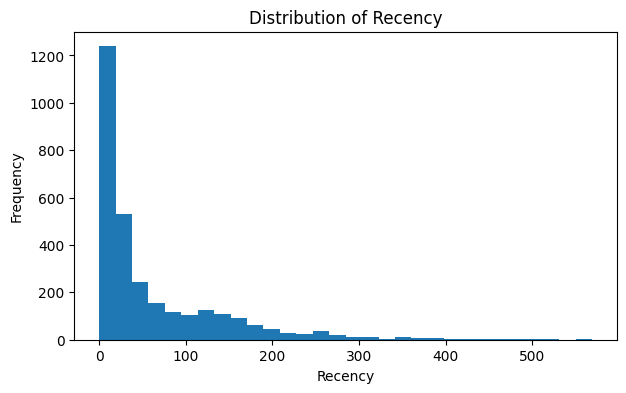

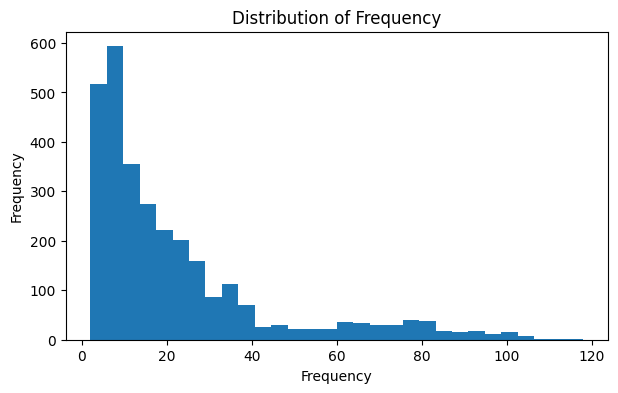

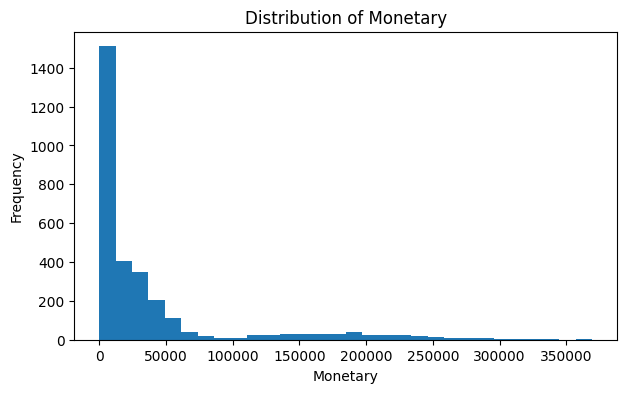

In [55]:
for col in ["Recency", "Frequency", "Monetary"]:
    plt.figure(figsize=(7, 4))
    plt.hist(rfm[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

In [56]:
rfm[["Recency", "Frequency", "Monetary"]].skew()

,0
Recency,2.141847
Frequency,1.798658
Monetary,2.518430


### Log Transformation


In [57]:
rfm_model = rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Log Transformation
rfm_log = np.log1p(rfm_model)

print("Before Log Transformation:")
display(rfm_model.skew().to_frame("Skewness"))

print("After Log Transformation:")
display(rfm_log.skew().to_frame("Skewness"))

Before Log Transformation:


,Skewness
Recency,2.141847
Frequency,1.798658
Monetary,2.518430


After Log Transformation:


,Skewness
Recency,-0.266000
Frequency,0.294426
Monetary,0.282121


### Standardization


In [58]:
from sklearn.preprocessing import StandardScaler

rfm_scaler = StandardScaler()
rfm_scaled = rfm_scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

rfm_scaled.describe().round(3)

,Recency,Frequency,Monetary
count,3000.000,3000.000,3000.000
mean,0.000,-0.000,-0.000
std,1.000,1.000,1.000
min,-2.190,-1.928,-4.118
25%,-0.709,-0.787,-0.776
50%,0.079,-0.055,-0.109
75%,0.850,0.713,0.676
max,2.086,2.356,2.334


## 3.4 Preparation for Customer Retention


### Feature Engineering


### Feature Window


In [59]:
# กำหนดวันสิ้นสุดของ Feature Window
feature_end_date = pd.Timestamp("2026-06-01")

# ใช้เฉพาะ Purchase และข้อมูลที่เกิดขึ้นไม่เกิน Feature Window
churn_transactions = transactions_clean[
    (transactions_clean["is_return"] == 0) &
    (transactions_clean["transaction_date"] <= feature_end_date)
].copy()

print("Feature window end:", feature_end_date.date())
print("Transactions:", len(churn_transactions))
print("Customers:", churn_transactions["customer_id"].nunique())

print(
    "Date range:",
    churn_transactions["transaction_date"].min(),
    "to",
    churn_transactions["transaction_date"].max()
)

Feature window end: 2026-06-01
Transactions: 56363
Customers: 2876
Date range: 2024-09-01 00:00:00 to 2026-06-01 00:00:00


### Behavioral Features


In [60]:
customer_features = (
    churn_transactions
    .groupby("customer_id")
    .agg(
        last_purchase=("transaction_date", "max"),
        frequency=("transaction_id", "nunique"),
        monetary=("net_amount", "sum"),
        avg_basket_value=("net_amount", "mean"),
        avg_units=("total_units", "mean"),
        total_discount=("discount_amount", "sum")
    )
    .reset_index()
)

# Recency คำนวณ ณ วันสุดท้ายของ Feature Window
customer_features["recency"] = (
    feature_end_date - customer_features["last_purchase"]
).dt.days

customer_features.head()

,customer_id,last_purchase,frequency,monetary,avg_basket_value,avg_units,total_discount,recency
0,C10001,2026-03-04,7,7401.33,1057.332857,9.714286,304.64,89
1,C10002,2026-05-31,7,3045.75,435.107143,6.000000,319.49,1
2,C10003,2026-03-30,4,3110.29,777.572500,3.250000,0.00,63
3,C10004,2026-05-31,5,2206.65,441.330000,3.600000,299.40,1
4,C10005,2026-04-28,11,6578.14,598.012727,7.545455,555.21,34


### Recent Purchase Features


In [61]:
def count_transactions_last_days(df, days, reference_date):
    start_date = reference_date - pd.Timedelta(days=days)

    return (
        df[df["transaction_date"] > start_date]
        .groupby("customer_id")["transaction_id"]
        .nunique()
    )

In [62]:
for days in [30, 90, 180, 365]:
    counts = count_transactions_last_days(
        churn_transactions,
        days,
        feature_end_date
    )

    customer_features[f"transactions_{days}d"] = (
        customer_features["customer_id"]
        .map(counts)
        .fillna(0)
        .astype(int)
    )

In [63]:
customer_features[
    [
        "customer_id",
        "recency",
        "frequency",
        "monetary",
        "transactions_30d",
        "transactions_90d",
        "transactions_180d",
        "transactions_365d"
    ]
].head(10)

,customer_id,recency,frequency,monetary,transactions_30d,transactions_90d,transactions_180d,transactions_365d
0,C10001,89,7,7401.33,0,1,2,7
1,C10002,1,7,3045.75,1,5,6,7
2,C10003,63,4,3110.29,0,1,2,4
3,C10004,1,5,2206.65,2,3,4,5
4,C10005,34,11,6578.14,0,1,2,7
5,C10006,1,11,6745.38,2,4,5,7
6,C10007,9,4,6800.87,1,3,4,4
7,C10009,89,2,771.43,0,1,2,2
8,C10010,28,15,11237.07,1,3,8,14
9,C10011,37,14,12091.99,0,3,7,11


### Churn Label


In [64]:
churn_dataset = customer_features.merge(
    churn_labels_clean[
        ["customer_id", "churn"]
    ],
    on="customer_id",
    how="left"
)

churn_dataset.head()

,customer_id,last_purchase,frequency,monetary,avg_basket_value,avg_units,total_discount,recency,transactions_30d,transactions_90d,transactions_180d,transactions_365d,churn
0,C10001,2026-03-04,7,7401.33,1057.332857,9.714286,304.64,89,0,1,2,7,1
1,C10002,2026-05-31,7,3045.75,435.107143,6.000000,319.49,1,1,5,6,7,0
2,C10003,2026-03-30,4,3110.29,777.572500,3.250000,0.00,63,0,1,2,4,1
3,C10004,2026-05-31,5,2206.65,441.330000,3.600000,299.40,1,2,3,4,5,0
4,C10005,2026-04-28,11,6578.14,598.012727,7.545455,555.21,34,0,1,2,7,0


In [65]:
print("Number of customers:", len(churn_dataset))

print("\nMissing churn labels:")
print(churn_dataset["churn"].isna().sum())

print("\nChurn distribution:")
print(churn_dataset["churn"].value_counts())

print("\nChurn percentage:")
print(
    churn_dataset["churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Number of customers: 2876

Missing churn labels:
0

Churn distribution:
churn
0    2133
1     743
Name: count, dtype: int64

Churn percentage:
churn
0    74.17
1    25.83
Name: proportion, dtype: float64


### Churn Label Balance Check


In [66]:
churn_transactions.groupby("customer_id")

In [67]:
all_customers = set(
    churn_labels_clean["customer_id"]
)

feature_customers = set(
    customer_features["customer_id"]
)

missing_customers = all_customers - feature_customers

print("All customers:", len(all_customers))
print("Customers with features:", len(feature_customers))
print("Missing customers:", len(missing_customers))

All customers: 3000
Customers with features: 2876
Missing customers: 124


In [68]:
missing_customer_info = churn_labels_clean[
    churn_labels_clean["customer_id"].isin(missing_customers)
][
    [
        "customer_id",
        "first_purchase_date",
        "last_purchase_date",
        "churn"
    ]
].copy()

display(missing_customer_info.head(20))

print("\nChurn distribution:")
print(
    missing_customer_info["churn"].value_counts()
)

,customer_id,first_purchase_date,last_purchase_date,churn
7,C10008,2026-06-05,2026-07-04,0
30,C10031,2026-06-15,2026-07-23,0
34,C10035,2026-06-16,2026-08-17,0
89,C10090,2026-06-09,2026-07-10,0
109,C10110,2026-07-26,2026-08-26,0
134,C10135,2026-06-18,2026-08-07,0
138,C10139,2026-07-05,2026-08-22,0
145,C10146,2026-06-18,2026-08-31,0
164,C10165,2026-06-28,2026-08-30,0
167,C10168,2026-07-15,2026-08-01,0



Churn distribution:
churn
0    124
Name: count, dtype: int64


In [69]:
print(
    missing_customer_info["first_purchase_date"]
    .describe()
)

count                              124
mean     2026-06-21 20:42:34.838709760
min                2026-06-02 00:00:00
25%                2026-06-14 00:00:00
50%                2026-06-21 00:00:00
75%                2026-06-29 00:00:00
max                2026-07-26 00:00:00
Name: first_purchase_date, dtype: object


### Eligible Customer Population

หลังจากสร้าง Feature จากข้อมูลในช่วง Feature Window พบว่าสามารถสร้างข้อมูลพฤติกรรมได้สำหรับลูกค้า **2,876 คน จากทั้งหมด 3,000 คน**

เมื่อตรวจสอบลูกค้า 124 คนที่ไม่มีข้อมูลใน Feature Window พบว่าลูกค้ากลุ่มนี้มีการซื้อสินค้าครั้งแรกตั้งแต่วันที่ **2 มิถุนายน 2026 เป็นต้นไป** ซึ่งเป็นช่วง Outcome Window โดยวันที่ซื้อครั้งแรกอยู่ระหว่าง 2 มิถุนายน 2026 ถึง 26 กรกฎาคม 2026

ดังนั้น ณ วันที่สิ้นสุด Feature Window (1 มิถุนายน 2026) ลูกค้าทั้ง 124 คนนี้ยังไม่มีประวัติการซื้อสินค้า และไม่สามารถสร้าง Behavioral Features เพื่อใช้ทำนายการเลิกซื้อได้

จึงกำหนด Modeling Population สำหรับ Customer Retention เป็นลูกค้า **2,876 คน** ที่มีประวัติการซื้ออย่างน้อยหนึ่งครั้งภายใน Feature Window

หลังจากเชื่อมกับ Churn Label พบว่า

- Non-Churn (`churn = 0`) = 2,133 คน หรือ 74.17%
- Churn (`churn = 1`) = 743 คน หรือ 25.83%

ข้อมูลจึงมี Class Imbalance ในระดับหนึ่ง และจะใช้ Precision, Recall, F1-Score, ROC-AUC และ PR-AUC ร่วมกับ Accuracy ในการประเมินโมเดล


In [70]:
churn_dataset.columns

Index(['customer_id', 'last_purchase', 'frequency', 'monetary',
       'avg_basket_value', 'avg_units', 'total_discount', 'recency',
       'transactions_30d', 'transactions_90d', 'transactions_180d',
       'transactions_365d', 'churn'],
      dtype='object')

### Feature Adjustment


In [71]:
customer_features["transactions_0_30d"] = (
    customer_features["transactions_30d"]
)

customer_features["transactions_31_90d"] = (
    customer_features["transactions_90d"]
    - customer_features["transactions_30d"]
)

customer_features["transactions_91_180d"] = (
    customer_features["transactions_180d"]
    - customer_features["transactions_90d"]
)

customer_features["transactions_181_365d"] = (
    customer_features["transactions_365d"]
    - customer_features["transactions_180d"]
)

In [72]:
customer_features["transactions_prev_90d"] = (
    customer_features["transactions_180d"]
    - customer_features["transactions_90d"]
)

customer_features["purchase_trend_90d"] = (
    customer_features["transactions_90d"]
    - customer_features["transactions_prev_90d"]
)

### Purchase Trend Feature


In [73]:
churn_dataset["purchase_trend_90d"] = (
    churn_dataset["customer_id"]
    .map(
        customer_features.set_index("customer_id")[
            "purchase_trend_90d"
        ]
    )
)

churn_dataset[
    [
        "customer_id",
        "transactions_90d",
        "transactions_180d",
        "purchase_trend_90d",
        "churn"
    ]
].head()

,customer_id,transactions_90d,transactions_180d,purchase_trend_90d,churn
0,C10001,1,2,0,1
1,C10002,5,6,4,0
2,C10003,1,2,0,1
3,C10004,3,4,2,0
4,C10005,1,2,0,0


In [74]:
print(
    churn_dataset["purchase_trend_90d"]
    .describe()
)

print(
    "\nMissing:",
    churn_dataset["purchase_trend_90d"].isna().sum()
)

count    2876.000000
mean        0.021558
std         2.911128
min       -13.000000
25%        -2.000000
50%         0.000000
75%         2.000000
max        15.000000
Name: purchase_trend_90d, dtype: float64

Missing: 0


### Modeling Feature Set


In [75]:
final_feature_columns = [
    "recency",
    "frequency",
    "monetary",
    "avg_basket_value",
    "avg_units",
    "total_discount",
    "transactions_30d",
    "transactions_90d",
    "transactions_365d",
    "purchase_trend_90d"
]

X_final = churn_dataset[
    final_feature_columns
].copy()

y_final = churn_dataset["churn"].copy()

print("X shape:", X_final.shape)
print("Missing values:")
print(X_final.isna().sum())

X shape: (2876, 10)
Missing values:
recency               0
frequency             0
monetary              0
avg_basket_value      0
avg_units             0
total_discount        0
transactions_30d      0
transactions_90d      0
transactions_365d     0
purchase_trend_90d    0
dtype: int64


# 4. Modeling


## 4.1 Increase Basket Size


### 4.1.1 Apriori


In [76]:
start_time = time.perf_counter()

frequent_apriori = apriori(
    basket_df,
    min_support=0.01,
    use_colnames=True
)

apriori_time = time.perf_counter() - start_time

#### Add itemset length


In [77]:
frequent_apriori["length"] = frequent_apriori["itemsets"].apply(
    lambda x: len(x)
)

frequent_apriori

,support,itemsets,length
0,0.041486,(Air Freshener),1
1,0.097195,(Apple 1kg),1
2,0.012494,(Baby Food Puree),1
3,0.014041,(Baby Formula),1
4,0.032449,(Baby Lotion),1
...,...,...,...
405,0.012237,"(Dog Food 3kg, Dog Treats, Pet Shampoo)",3
406,0.019955,"(Fresh Berries Pack, Yogurt Cup, Granola)",3
407,0.013192,"(Green Tea Bags, Honey Jar, Lemon 500g)",3
408,0.020834,"(Mouthwash, Toothpaste, Toothbrush)",3


In [78]:
print("Number of Frequent Itemsets:", len(frequent_apriori))
print(f"Apriori Runtime: {apriori_time:.4f} seconds")

frequent_apriori.sort_values(
    by="support",
    ascending=False
).head(10)

Number of Frequent Itemsets: 410
Apriori Runtime: 23.9524 seconds


,support,itemsets,length
38,0.185777,(Fresh Milk 1L),1
69,0.183306,(Sandwich Bread),1
88,0.150826,(Yogurt Cup),1
13,0.146748,(Butter),1
32,0.136467,(Egg Tray 10),1
62,0.130629,(Potato Chips),1
6,0.117104,(Banana Bunch),1
45,0.114041,(Instant Noodles 5pk),1
18,0.110250,(Chicken Breast 500g),1
11,0.103624,(Bottled Water 6pk),1


### 4.1.2 Association Rules — Apriori


In [79]:
rules_apriori = association_rules(
    frequent_apriori,
    metric="confidence",
    min_threshold=0.30
)

rules_apriori.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(Baby Lotion),(Baby Wipes),0.032449,0.060591,0.021425,0.660280,10.897270,1.0,0.019459,2.765247,0.938693,0.299174,0.638369,0.506942
1,(Baby Wipes),(Baby Lotion),0.060591,0.032449,0.021425,0.353604,10.897270,1.0,0.019459,1.496839,0.966814,0.299174,0.331925,0.506942
2,(Diapers Pack),(Baby Lotion),0.066550,0.032449,0.021804,0.327637,10.097046,1.0,0.019645,1.439032,0.965195,0.282459,0.305088,0.499800
3,(Baby Lotion),(Diapers Pack),0.032449,0.066550,0.021804,0.671963,10.097046,1.0,0.019645,2.845559,0.931177,0.282459,0.648575,0.499800
4,(Diapers Pack),(Baby Wipes),0.066550,0.060591,0.031418,0.472089,7.791364,1.0,0.027385,1.779484,0.933797,0.328212,0.438039,0.495304


In [80]:
rules_apriori_result = rules_apriori[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
].copy()

rules_apriori_result.head(10)

,antecedents,consequents,support,confidence,lift
0,(Baby Lotion),(Baby Wipes),0.021425,0.660280,10.897270
1,(Baby Wipes),(Baby Lotion),0.021425,0.353604,10.897270
2,(Diapers Pack),(Baby Lotion),0.021804,0.327637,10.097046
3,(Baby Lotion),(Diapers Pack),0.021804,0.671963,10.097046
4,(Diapers Pack),(Baby Wipes),0.031418,0.472089,7.791364
5,(Baby Wipes),(Diapers Pack),0.031418,0.518519,7.791364
6,(Beer 6pk),(Potato Chips),0.044155,0.472958,3.620610
7,(Potato Chips),(Beer 6pk),0.044155,0.338015,3.620610
8,(Salsa Dip),(Beer 6pk),0.026475,0.605199,6.482523
9,(Butter),(Sandwich Bread),0.068961,0.469932,2.563653


#### Positive-lift rules


In [81]:
rules_apriori_result = rules_apriori_result[
    rules_apriori_result["lift"] > 1
].sort_values(
    by=["lift", "confidence"],
    ascending=False
)

rules_apriori_result.head(10)

,antecedents,consequents,support,confidence,lift
77,"(Dog Food 3kg, Pet Shampoo)",(Dog Treats),0.012237,0.963007,22.553381
76,"(Dog Food 3kg, Dog Treats)",(Pet Shampoo),0.012237,0.523686,20.767941
79,(Pet Shampoo),"(Dog Food 3kg, Dog Treats)",0.012237,0.485268,20.767941
49,"(Diapers Pack, Baby Wipes)",(Baby Lotion),0.021152,0.673263,20.748442
52,(Baby Lotion),"(Diapers Pack, Baby Wipes)",0.021152,0.651869,20.748442
66,"(Coffee Beans 250g, Coffee Creamer)",(Coffee Filter Paper),0.029795,0.974702,17.472580
69,(Coffee Filter Paper),"(Coffee Beans 250g, Coffee Creamer)",0.029795,0.534113,17.472580
78,"(Dog Treats, Pet Shampoo)",(Dog Food 3kg),0.012237,0.975816,17.295103
65,"(Coffee Beans 250g, Coffee Filter Paper)",(Coffee Creamer),0.029795,0.742350,16.067598
70,(Coffee Creamer),"(Coffee Beans 250g, Coffee Filter Paper)",0.029795,0.644897,16.067598


In [82]:
print("Number of Apriori Rules:", len(rules_apriori_result))

Number of Apriori Rules: 96


### 4.1.3 FP-Growth


เปรียบเทียบด้วยเกณฑ์เดียวกับ Apriori ทั้งหมด

In [83]:
start_time = time.perf_counter()

frequent_fpgrowth = fpgrowth(
    basket_df,
    min_support=0.01,
    use_colnames=True
)

fpgrowth_time = time.perf_counter() - start_time

In [84]:
frequent_fpgrowth["length"] = frequent_fpgrowth["itemsets"].apply(
    lambda x: len(x)
)

frequent_fpgrowth.head(10)

,support,itemsets,length
0,0.100713,(Spaghetti Pasta),1
1,0.088476,(Pasta Sauce),1
2,0.058923,(Parmesan Cheese),1
3,0.063381,(Honey Jar),1
4,0.062244,(Green Tea Bags),1
5,0.047475,(Lemon 500g),1
6,0.073601,(Cooking Oil 1L),1
7,0.072388,(Conditioner),1
8,0.070872,(Dish Soap),1
9,0.045550,(Peanut Butter),1


In [85]:
print("Number of Frequent Itemsets:", len(frequent_fpgrowth))
print(f"FP-Growth Runtime: {fpgrowth_time:.4f} seconds")

Number of Frequent Itemsets: 410
FP-Growth Runtime: 100.7044 seconds


### 4.1.4 Association Rules — FP-Growth


In [86]:
rules_fpgrowth = association_rules(
    frequent_fpgrowth,
    metric="confidence",
    min_threshold=0.30
)

rules_fpgrowth_result = rules_fpgrowth[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
].copy()

In [87]:
rules_fpgrowth_result = rules_fpgrowth_result[
    rules_fpgrowth_result["lift"] > 1
].sort_values(
    by=["lift", "confidence"],
    ascending=False
)

rules_fpgrowth_result.head(10)

,antecedents,consequents,support,confidence,lift
71,"(Dog Food 3kg, Pet Shampoo)",(Dog Treats),0.012237,0.963007,22.553381
70,"(Dog Food 3kg, Dog Treats)",(Pet Shampoo),0.012237,0.523686,20.767941
73,(Pet Shampoo),"(Dog Food 3kg, Dog Treats)",0.012237,0.485268,20.767941
59,"(Diapers Pack, Baby Wipes)",(Baby Lotion),0.021152,0.673263,20.748442
62,(Baby Lotion),"(Diapers Pack, Baby Wipes)",0.021152,0.651869,20.748442
83,"(Coffee Beans 250g, Coffee Creamer)",(Coffee Filter Paper),0.029795,0.974702,17.472580
86,(Coffee Filter Paper),"(Coffee Beans 250g, Coffee Creamer)",0.029795,0.534113,17.472580
72,"(Dog Treats, Pet Shampoo)",(Dog Food 3kg),0.012237,0.975816,17.295103
82,"(Coffee Beans 250g, Coffee Filter Paper)",(Coffee Creamer),0.029795,0.742350,16.067598
87,(Coffee Creamer),"(Coffee Beans 250g, Coffee Filter Paper)",0.029795,0.644897,16.067598


In [88]:
print("Number of FP-Growth Rules:", len(rules_fpgrowth_result))

Number of FP-Growth Rules: 96


### 4.1.5 Algorithm Comparison


#### Runtime and frequent itemsets comparison


In [89]:
comparison = pd.DataFrame({
    "Algorithm": ["Apriori", "FP-Growth"],
    "Runtime (seconds)": [
        apriori_time,
        fpgrowth_time
    ],
    "Frequent Itemsets": [
        len(frequent_apriori),
        len(frequent_fpgrowth)
    ],
    "Association Rules (Lift > 1)": [
        len(rules_apriori_result),
        len(rules_fpgrowth_result)
    ]
})

comparison

,Algorithm,Runtime (seconds),Frequent Itemsets,Association Rules (Lift > 1)
0,Apriori,23.952413,410,96
1,FP-Growth,100.704374,410,96


In [90]:
apriori_pairs = set(
    zip(
        rules_apriori_result["antecedents"].astype(str),
        rules_apriori_result["consequents"].astype(str)
    )
)

fpgrowth_pairs = set(
    zip(
        rules_fpgrowth_result["antecedents"].astype(str),
        rules_fpgrowth_result["consequents"].astype(str)
    )
)

print(
    "Same association rules:",
    apriori_pairs == fpgrowth_pairs
)

Same association rules: False


### 4.1.6 Top Association Rules


In [91]:
def format_itemset(itemset):
    return ", ".join(sorted(list(itemset)))

### Apriori

In [92]:
top_apriori = rules_apriori_result.copy()

top_apriori["antecedents"] = (
    top_apriori["antecedents"].apply(format_itemset)
)

top_apriori["consequents"] = (
    top_apriori["consequents"].apply(format_itemset)
)

top_apriori[
    ["antecedents", "consequents",
     "support", "confidence", "lift"]
].head(10)

,antecedents,consequents,support,confidence,lift
77,"Dog Food 3kg, Pet Shampoo",Dog Treats,0.012237,0.963007,22.553381
76,"Dog Food 3kg, Dog Treats",Pet Shampoo,0.012237,0.523686,20.767941
79,Pet Shampoo,"Dog Food 3kg, Dog Treats",0.012237,0.485268,20.767941
49,"Baby Wipes, Diapers Pack",Baby Lotion,0.021152,0.673263,20.748442
52,Baby Lotion,"Baby Wipes, Diapers Pack",0.021152,0.651869,20.748442
66,"Coffee Beans 250g, Coffee Creamer",Coffee Filter Paper,0.029795,0.974702,17.472580
69,Coffee Filter Paper,"Coffee Beans 250g, Coffee Creamer",0.029795,0.534113,17.472580
78,"Dog Treats, Pet Shampoo",Dog Food 3kg,0.012237,0.975816,17.295103
65,"Coffee Beans 250g, Coffee Filter Paper",Coffee Creamer,0.029795,0.742350,16.067598
70,Coffee Creamer,"Coffee Beans 250g, Coffee Filter Paper",0.029795,0.644897,16.067598


### FP-Growth

In [93]:
top_fpgrowth = rules_fpgrowth_result.copy()

top_fpgrowth["antecedents"] = (
    top_fpgrowth["antecedents"].apply(format_itemset)
)

top_fpgrowth["consequents"] = (
    top_fpgrowth["consequents"].apply(format_itemset)
)

top_fpgrowth[
    ["antecedents", "consequents",
     "support", "confidence", "lift"]
].head(10)

,antecedents,consequents,support,confidence,lift
71,"Dog Food 3kg, Pet Shampoo",Dog Treats,0.012237,0.963007,22.553381
70,"Dog Food 3kg, Dog Treats",Pet Shampoo,0.012237,0.523686,20.767941
73,Pet Shampoo,"Dog Food 3kg, Dog Treats",0.012237,0.485268,20.767941
59,"Baby Wipes, Diapers Pack",Baby Lotion,0.021152,0.673263,20.748442
62,Baby Lotion,"Baby Wipes, Diapers Pack",0.021152,0.651869,20.748442
83,"Coffee Beans 250g, Coffee Creamer",Coffee Filter Paper,0.029795,0.974702,17.472580
86,Coffee Filter Paper,"Coffee Beans 250g, Coffee Creamer",0.029795,0.534113,17.472580
72,"Dog Treats, Pet Shampoo",Dog Food 3kg,0.012237,0.975816,17.295103
82,"Coffee Beans 250g, Coffee Filter Paper",Coffee Creamer,0.029795,0.742350,16.067598
87,Coffee Creamer,"Coffee Beans 250g, Coffee Filter Paper",0.029795,0.644897,16.067598


#### Selected Product Associations


In [94]:
pair_rules = rules_fpgrowth_result[
    (rules_fpgrowth_result["antecedents"].apply(len) == 1) &
    (rules_fpgrowth_result["consequents"].apply(len) == 1)
].copy()

In [95]:
top_pair_rules = pair_rules.copy()

top_pair_rules["antecedents"] = (
    top_pair_rules["antecedents"].apply(format_itemset)
)

top_pair_rules["consequents"] = (
    top_pair_rules["consequents"].apply(format_itemset)
)

top_pair_rules = top_pair_rules[
    ["antecedents", "consequents",
     "support", "confidence", "lift"]
].head(10)

top_pair_rules

,antecedents,consequents,support,confidence,lift
80,Coffee Creamer,Coffee Filter Paper,0.030129,0.652117,11.689890
81,Coffee Filter Paper,Coffee Creamer,0.030129,0.540092,11.689890
69,Pet Shampoo,Dog Treats,0.012540,0.497294,11.646499
56,Baby Lotion,Baby Wipes,0.021425,0.660280,10.897270
57,Baby Wipes,Baby Lotion,0.021425,0.353604,10.897270
55,Baby Lotion,Diapers Pack,0.021804,0.671963,10.097046
54,Diapers Pack,Baby Lotion,0.021804,0.327637,10.097046
75,Dog Treats,Dog Food 3kg,0.023366,0.547230,9.698959
74,Dog Food 3kg,Dog Treats,0.023366,0.414136,9.698959
77,Coffee Filter Paper,Coffee Beans 250g,0.040136,0.719489,9.412874


## 4.2 Customer Segmentation


### 4.2.1 Selecting K


In [96]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [97]:
# range 2-10
k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(rfm_scaled, labels)
    )

In [98]:
k_evaluation = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

k_evaluation

,K,Inertia,Silhouette Score
0,2,4506.714072,0.431668
1,3,3251.525660,0.356767
2,4,2299.412737,0.377032
3,5,1850.066117,0.371630
4,6,1564.481983,0.360247
5,7,1324.580959,0.364226
6,8,1198.719089,0.345207
7,9,1077.214088,0.355627
8,10,967.661738,0.353381


#### Elbow


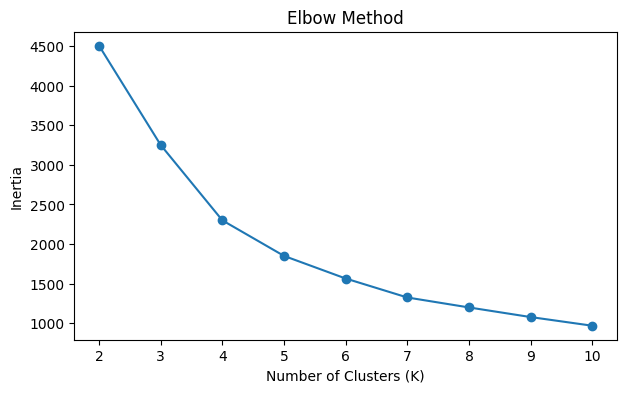

In [99]:
plt.figure(figsize=(7, 4))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.xticks(list(k_values))
plt.show()

#### Silhouette


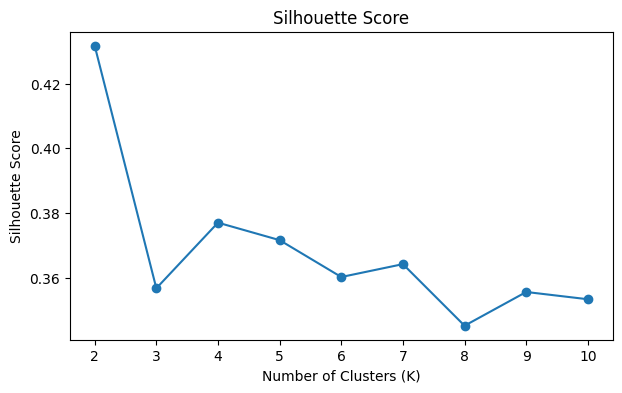

In [100]:
plt.figure(figsize=(7, 4))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")

plt.xticks(list(k_values))
plt.show()

### 4.2.2 Final K-Means (K=4)


In [101]:
final_k = 4

kmeans = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,customer_id,Recency,Frequency,Monetary,Cluster
0,C10001,180,7,7401.33,2
1,C10002,4,8,3282.67,1
2,C10003,154,4,3110.29,2
3,C10004,10,6,2507.13,1
4,C10005,4,12,6843.47,1


In [102]:
cluster_counts = (
    rfm["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_counts

,count
Cluster,
0,887
1,587
2,863
3,663


### 4.2.3 Cluster Profiling


In [103]:
cluster_profile = (
    rfm
    .groupby("Cluster")
    .agg(
        Customers=("customer_id", "count"),
        Recency_Mean=("Recency", "mean"),
        Frequency_Mean=("Frequency", "mean"),
        Monetary_Mean=("Monetary", "mean")
    )
    .round(2)
)

cluster_profile

,Customers,Recency_Mean,Frequency_Mean,Monetary_Mean
Cluster,,,,
0,887,86.63,21.53,26880.32
1,587,8.61,9.01,7157.91
2,863,112.38,6.27,4399.76
3,663,7.48,54.53,122217.69


In [104]:
cluster_profile = (
    rfm
    .groupby("Cluster")
    .agg(
        Customers=("customer_id", "count"),

        Recency_Mean=("Recency", "mean"),
        Recency_Median=("Recency", "median"),

        Frequency_Mean=("Frequency", "mean"),
        Frequency_Median=("Frequency", "median"),

        Monetary_Mean=("Monetary", "mean"),
        Monetary_Median=("Monetary", "median")
    )
    .round(2)
)

cluster_profile

,Customers,Recency_Mean,Recency_Median,Frequency_Mean,Frequency_Median,Monetary_Mean,Monetary_Median
Cluster,,,,,,,
0,887,86.63,59.0,21.53,20.0,26880.32,24106.88
1,587,8.61,7.0,9.01,8.0,7157.91,6029.32
2,863,112.38,80.0,6.27,6.0,4399.76,3840.44
3,663,7.48,5.0,54.53,52.0,122217.69,111475.86


### 4.2.4 Segment Naming

จากการใช้ K-Means แบ่งกลุ่มลูกค้าด้วยข้อมูล Recency, Frequency และ Monetary สามารถแบ่งลูกค้าออกเป็น 4 กลุ่มที่มีพฤติกรรมแตกต่างกัน ดังนี้

- **Cluster 0 — At-Risk Valuable Customers:** มีลูกค้า 887 คน เคยมีความถี่ในการซื้อและมูลค่าการใช้จ่ายค่อนข้างสูง โดยซื้อเฉลี่ย 21.53 ครั้ง และมียอดใช้จ่ายเฉลี่ย 26,880.32 บาท อย่างไรก็ตาม มี Recency เฉลี่ย 86.63 วัน แสดงว่าลูกค้ากลุ่มนี้เคยมีคุณค่าต่อธุรกิจ แต่เริ่มห่างหายจากการซื้อสินค้า จึงเหมาะกับการทำแคมเปญกระตุ้นให้กลับมาซื้ออีกครั้ง (Win-back Campaign)

- **Cluster 1 — Recent / Developing Customers:** มีลูกค้า 587 คน และมี Recency เฉลี่ยเพียง 8.61 วัน แสดงว่ายังเป็นลูกค้าที่มีการซื้อสินค้าในช่วงไม่นานมานี้ แต่มี Frequency และ Monetary อยู่ในระดับค่อนข้างต่ำเมื่อเทียบกับกลุ่มลูกค้ามูลค่าสูง โดยซื้อเฉลี่ย 9.01 ครั้ง และใช้จ่ายเฉลี่ย 7,157.91 บาท จึงเป็นกลุ่มที่สามารถกระตุ้นให้เกิดการซื้อซ้ำและเพิ่มมูลค่าการใช้จ่ายได้

- **Cluster 2 — Inactive / Low-Value Customers:** มีลูกค้า 863 คน มี Recency เฉลี่ยสูงที่สุดที่ 112.38 วัน ขณะที่มี Frequency เฉลี่ยเพียง 6.27 ครั้ง และ Monetary เฉลี่ย 4,399.76 บาท ซึ่งต่ำที่สุดในทุกกลุ่ม แสดงถึงกลุ่มลูกค้าที่ซื้อไม่บ่อยและไม่ได้กลับมาซื้อสินค้าเป็นระยะเวลานาน

- **Cluster 3 — High-Value / Loyal Customers:** มีลูกค้า 663 คน มี Recency เฉลี่ยเพียง 7.48 วัน ขณะที่มี Frequency เฉลี่ยสูงถึง 54.53 ครั้ง และ Monetary เฉลี่ย 122,217.69 บาท ซึ่งสูงที่สุดในทุกกลุ่ม แสดงถึงกลุ่มลูกค้าที่ซื้อสินค้าอย่างต่อเนื่องและสร้างมูลค่าให้กับธุรกิจสูง จึงเป็นกลุ่มสำคัญที่ธุรกิจควรรักษาความสัมพันธ์และสร้างความภักดีในระยะยาว


### 4.2.5 Visualization


#### RFM by Cluster


In [105]:
# คำนวณค่าเฉลี่ย RFM ของแต่ละ Cluster
cluster_rfm_mean = (
    rfm.groupby("Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ]
    .mean()
)

# Normalize ด้วยค่าเฉลี่ยของลูกค้าทั้งหมด
overall_mean = rfm[
    ["Recency", "Frequency", "Monetary"]
].mean()

cluster_relative = cluster_rfm_mean / overall_mean

cluster_relative.round(2)

,Recency,Frequency,Monetary
Cluster,,,
0,1.41,0.98,0.71
1,0.14,0.41,0.19
2,1.83,0.29,0.12
3,0.12,2.48,3.25


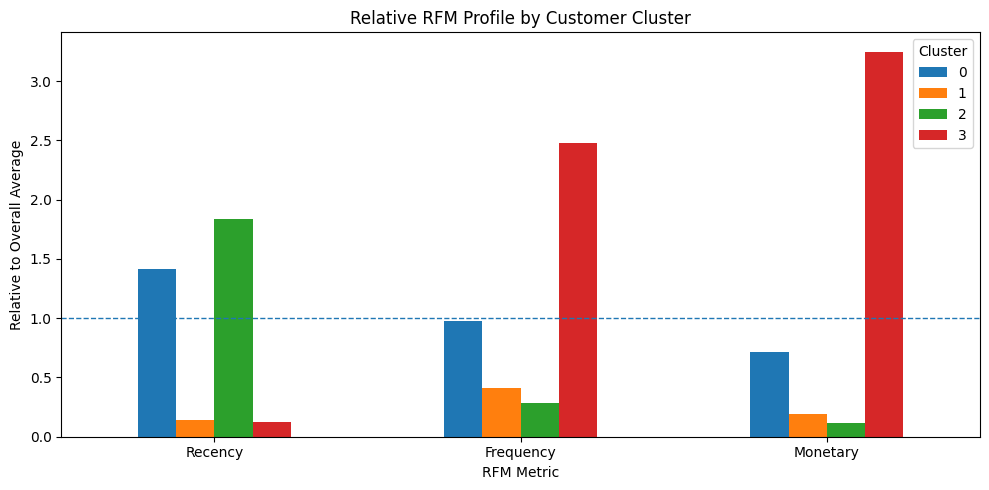

In [106]:
cluster_relative.T.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.axhline(
    y=1,
    linestyle="--",
    linewidth=1
)

plt.title("Relative RFM Profile by Customer Cluster")
plt.xlabel("RFM Metric")
plt.ylabel("Relative to Overall Average")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

#### Customer Count by Cluster


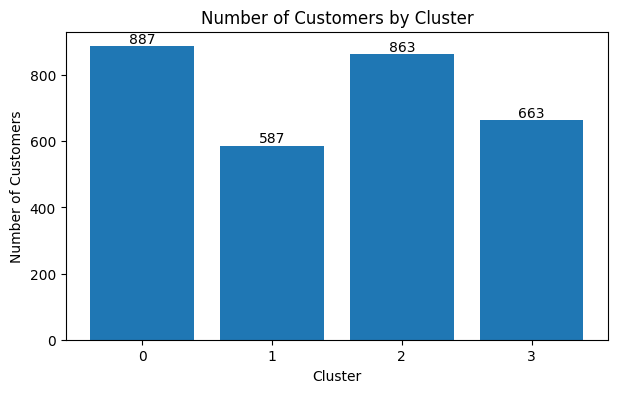

In [107]:
cluster_counts = (
    rfm["Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 4))

plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.title("Number of Customers by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

for i, value in enumerate(cluster_counts.values):
    plt.text(
        i,
        value + 10,
        str(value),
        ha="center"
    )

plt.show()

#### Add Segment Name


In [108]:
cluster_names = {
    0: "At-Risk Valuable",
    1: "Recent / Developing",
    2: "Inactive / Low-Value",
    3: "High-Value / Loyal"
}

rfm["Segment"] = rfm["Cluster"].map(cluster_names)

rfm.head()

,customer_id,Recency,Frequency,Monetary,Cluster,Segment
0,C10001,180,7,7401.33,2,Inactive / Low-Value
1,C10002,4,8,3282.67,1,Recent / Developing
2,C10003,154,4,3110.29,2,Inactive / Low-Value
3,C10004,10,6,2507.13,1,Recent / Developing
4,C10005,4,12,6843.47,1,Recent / Developing


In [109]:
rfm["Segment"].value_counts()

,count
Segment,
At-Risk Valuable,887
Inactive / Low-Value,863
High-Value / Loyal,663
Recent / Developing,587


#### Segment Business Actions

จากผลการแบ่งกลุ่มลูกค้าด้วย RFM และ K-Means สามารถกำหนดแนวทางในการบริหารลูกค้าแต่ละกลุ่มได้ดังนี้

| Segment | ลักษณะสำคัญ | แนวทางทางธุรกิจ |
|---|---|---|
| **At-Risk Valuable** | เคยซื้อค่อนข้างบ่อยและมียอดใช้จ่ายค่อนข้างสูง แต่ไม่ได้กลับมาซื้อเป็นระยะเวลานาน | ใช้ Win-back Campaign เช่น คูปองส่วนลดเฉพาะบุคคล โปรโมชั่นสำหรับการกลับมาซื้อ หรือการแจ้งเตือนสินค้าและสิทธิประโยชน์ |
| **Recent / Developing** | เพิ่งมีการซื้อสินค้าไม่นาน แต่จำนวนครั้งและยอดใช้จ่ายยังไม่สูง | กระตุ้นการซื้อซ้ำด้วยโปรโมชั่นครั้งถัดไป Cross-selling หรือ Recommendation เพื่อพัฒนาให้เป็นลูกค้าประจำ |
| **Inactive / Low-Value** | ซื้อไม่บ่อย มูลค่าการใช้จ่ายต่ำ และไม่ได้กลับมาซื้อเป็นเวลานาน | ใช้แคมเปญ Re-engagement ที่มีต้นทุนต่ำ และหลีกเลี่ยงการใช้ Promotion Cost สูงกับลูกค้าที่มีโอกาสตอบสนองต่ำ |
| **High-Value / Loyal** | ซื้อสินค้าอย่างต่อเนื่อง มีความถี่และยอดใช้จ่ายสูงที่สุด | ให้สิทธิพิเศษ Loyalty Program, VIP Rewards, Early Access และ Personalized Offers เพื่อรักษาลูกค้าที่สร้างมูลค่าสูง |


#### Segmentation Summary

จากการวิเคราะห์พฤติกรรมลูกค้าด้วย RFM และ K-Means สามารถแบ่งลูกค้าจำนวน 3,000 คนออกเป็น **4 กลุ่ม** ที่มีพฤติกรรมแตกต่างกันอย่างชัดเจน

- **At-Risk Valuable Customers:** 887 คน เป็นลูกค้าที่เคยมีมูลค่าและซื้อค่อนข้างบ่อย แต่เริ่มห่างหายจากการซื้อ
- **Recent / Developing Customers:** 587 คน เป็นลูกค้าที่เพิ่งซื้อสินค้าไม่นาน แต่ยังมีความถี่และมูลค่าการซื้อไม่สูง
- **Inactive / Low-Value Customers:** 863 คน เป็นลูกค้าที่ซื้อไม่บ่อย มูลค่าต่ำ และห่างหายจากการซื้อเป็นเวลานาน
- **High-Value / Loyal Customers:** 663 คน เป็นลูกค้าที่ซื้ออย่างต่อเนื่อง มีความถี่และมูลค่าการใช้จ่ายสูงที่สุด

ผลการแบ่งกลุ่มช่วยให้ธุรกิจสามารถกำหนดกลยุทธ์ที่แตกต่างกันตามพฤติกรรมของลูกค้า เช่น การรักษาลูกค้ามูลค่าสูง การพัฒนาลูกค้าใหม่ให้เกิดการซื้อซ้ำ และการกระตุ้นลูกค้าที่เริ่มห่างหายให้กลับมาซื้อสินค้าอีกครั้ง

อย่างไรก็ตาม กลุ่มที่มี Recency สูงจากการทำ Clustering ยังไม่สามารถสรุปได้โดยตรงว่าเป็นลูกค้าที่ Churn เนื่องจากการแบ่งกลุ่มในขั้นตอนนี้เป็น Unsupervised Learning และไม่ได้ใช้ Churn Label ในการสร้างโมเดล การวิเคราะห์ความเสี่ยงในการเลิกซื้อจะดำเนินการต่อในส่วน Customer Retention


## 4.3 Customer Retention


### 4.3.1 Feature Set


In [110]:
feature_columns = [
    "recency",
    "frequency",
    "monetary",
    "avg_basket_value",
    "avg_units",
    "total_discount",
    "transactions_30d",
    "transactions_90d",
    "transactions_180d",
    "transactions_365d"
]

X = churn_dataset[feature_columns].copy()
y = churn_dataset["churn"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())

X shape: (2876, 10)
y shape: (2876,)


,recency,frequency,monetary,avg_basket_value,avg_units,total_discount,transactions_30d,transactions_90d,transactions_180d,transactions_365d
0,89,7,7401.33,1057.332857,9.714286,304.64,0,1,2,7
1,1,7,3045.75,435.107143,6.000000,319.49,1,5,6,7
2,63,4,3110.29,777.572500,3.250000,0.00,0,1,2,4
3,1,5,2206.65,441.330000,3.600000,299.40,2,3,4,5
4,34,11,6578.14,598.012727,7.545455,555.21,0,1,2,7


#### Missing and Infinite Check


In [111]:
print("Missing values:")
print(X.isna().sum())

print("\nInfinite values:")
print(
    pd.Series(
        np.isinf(X).sum(),
        index=X.columns
    )
)

Missing values:
recency              0
frequency            0
monetary             0
avg_basket_value     0
avg_units            0
total_discount       0
transactions_30d     0
transactions_90d     0
transactions_180d    0
transactions_365d    0
dtype: int64

Infinite values:
recency              0
frequency            0
monetary             0
avg_basket_value     0
avg_units            0
total_discount       0
transactions_30d     0
transactions_90d     0
transactions_180d    0
transactions_365d    0
dtype: int64


### 4.3.2 Train / Test Split


In [112]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTrain churn rate:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTest churn rate:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (2300, 10)
Test set: (576, 10)

Train churn rate:
churn
0    0.742
1    0.258
Name: proportion, dtype: float64

Test churn rate:
churn
0    0.741
1    0.259
Name: proportion, dtype: float64


### 4.3.3 Feature Scaling


In [113]:
churn_scaler = StandardScaler()

X_train_scaled = churn_scaler.fit_transform(X_train)
X_test_scaled = churn_scaler.transform(X_test)

### 4.3.4 Baseline Logistic Regression


In [114]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

LogisticRegression(max_iter=1000, random_state=42)

#### Predict Class and Probability


In [115]:
y_pred = logistic_model.predict(
    X_test_scaled
)

y_prob = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

In [116]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-Score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC   :", round(average_precision_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.809
Precision: 0.7294
Recall   : 0.4161
F1-Score : 0.5299
ROC-AUC  : 0.8369
PR-AUC   : 0.6753

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.95      0.88       427
           1       0.73      0.42      0.53       149

    accuracy                           0.81       576
   macro avg       0.78      0.68      0.71       576
weighted avg       0.80      0.81      0.79       576



In [117]:
cm = confusion_matrix(
    y_test,
    y_pred
)

cm

array([[404,  23],
       [ 87,  62]])

### 4.3.5 Balanced Logistic Regression


In [118]:
logistic_balanced = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

logistic_balanced.fit(
    X_train_scaled,
    y_train
)

y_pred_balanced = logistic_balanced.predict(
    X_test_scaled
)

y_prob_balanced = logistic_balanced.predict_proba(
    X_test_scaled
)[:, 1]

In [119]:
print("Accuracy :", round(accuracy_score(y_test, y_pred_balanced), 4))
print("Precision:", round(precision_score(y_test, y_pred_balanced), 4))
print("Recall   :", round(recall_score(y_test, y_pred_balanced), 4))
print("F1-Score :", round(f1_score(y_test, y_pred_balanced), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_balanced), 4))
print("PR-AUC   :", round(average_precision_score(y_test, y_prob_balanced), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_balanced
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_balanced
    )
)

Accuracy : 0.7552
Precision: 0.5192
Recall   : 0.7248
F1-Score : 0.605
ROC-AUC  : 0.8375
PR-AUC   : 0.6676

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.77      0.82       427
           1       0.52      0.72      0.61       149

    accuracy                           0.76       576
   macro avg       0.70      0.75      0.71       576
weighted avg       0.79      0.76      0.77       576


Confusion Matrix:
[[327 100]
 [ 41 108]]


#### Logistic Regression Comparison

เริ่มต้นด้วย Logistic Regression แบบปกติเป็น Baseline Model พบว่าโมเดลมี Accuracy 80.90% และ ROC-AUC 0.8369 แต่สามารถตรวจพบลูกค้าที่ Churn จริงได้เพียง 41.61% (Recall) โดยจากลูกค้า Churn จริง 149 คน โมเดลตรวจพบ 62 คน และพลาด 87 คน

เนื่องจากข้อมูลมีสัดส่วน Churn ต่ำกว่า Non-Churn จึงทดลอง Logistic Regression โดยกำหนด `class_weight="balanced"` เพื่อเพิ่มความสำคัญให้กับกลุ่ม Churn

หลังปรับ Class Weight พบว่า Recall ของ Churn เพิ่มขึ้นจาก 41.61% เป็น 72.48% และ F1-Score เพิ่มจาก 0.5299 เป็น 0.6050 โดยโมเดลสามารถตรวจพบลูกค้า Churn ได้ 108 จาก 149 คน และลดจำนวน False Negative จาก 87 เหลือ 41 คน

อย่างไรก็ตาม Precision ลดลงจาก 72.94% เป็น 51.92% และ Accuracy ลดลงจาก 80.90% เป็น 75.52% เนื่องจากโมเดลมีแนวโน้มระบุลูกค้าว่าเสี่ยง Churn มากขึ้น ส่งผลให้ False Positive เพิ่มขึ้น

สำหรับปัญหา Customer Retention การตรวจพบลูกค้าที่มีความเสี่ยง Churn ให้ได้มากที่สุดมีความสำคัญ เนื่องจาก False Negative หมายถึงลูกค้าที่มีความเสี่ยงแต่ไม่ได้รับการระบุเพื่อดำเนินมาตรการรักษาลูกค้า ดังนั้น Balanced Logistic Regression จึงถูกเลือกเป็นโมเดลหลักสำหรับการวิเคราะห์ในขั้นตอนถัดไป


### 4.3.6 Purchase Trend Experiment


#### Split and Scale with Trend Feature


In [120]:
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final,
    y_final,
    test_size=0.20,
    random_state=42,
    stratify=y_final
)

scaler_final = StandardScaler()

X_train_final_scaled = scaler_final.fit_transform(
    X_train_final
)

X_test_final_scaled = scaler_final.transform(
    X_test_final
)

#### Train Final Model


In [121]:
logistic_final = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

logistic_final.fit(
    X_train_final_scaled,
    y_train_final
)

y_pred_final = logistic_final.predict(
    X_test_final_scaled
)

y_prob_final = logistic_final.predict_proba(
    X_test_final_scaled
)[:, 1]

In [122]:
final_metrics = {
    "Accuracy": accuracy_score(
        y_test_final, y_pred_final
    ),
    "Precision": precision_score(
        y_test_final, y_pred_final
    ),
    "Recall": recall_score(
        y_test_final, y_pred_final
    ),
    "F1-Score": f1_score(
        y_test_final, y_pred_final
    ),
    "ROC-AUC": roc_auc_score(
        y_test_final, y_prob_final
    ),
    "PR-AUC": average_precision_score(
        y_test_final, y_prob_final
    )
}

for metric, value in final_metrics.items():
    print(f"{metric:10s}: {value:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_final,
        y_pred_final
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_final,
        y_pred_final
    )
)

Accuracy  : 0.7569
Precision : 0.5217
Recall    : 0.7248
F1-Score  : 0.6067
ROC-AUC   : 0.8377
PR-AUC    : 0.6675

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.77      0.82       427
           1       0.52      0.72      0.61       149

    accuracy                           0.76       576
   macro avg       0.71      0.75      0.72       576
weighted avg       0.79      0.76      0.77       576


Confusion Matrix:
[[328  99]
 [ 41 108]]


# 5. Evaluation


## 5.1 Increase Basket Size

- Apriori vs FP-Growth
- Support / Confidence / Lift
- Selected Product Associations
- Business interpretation


In [123]:
# สรุปผลการเปรียบเทียบ Apriori และ FP-Growth
association_evaluation = pd.DataFrame({
    "Algorithm": ["Apriori", "FP-Growth"],
    "Runtime (seconds)": [apriori_time, fpgrowth_time],
    "Frequent Itemsets": [
        len(frequent_apriori),
        len(frequent_fpgrowth)
    ],
    "Association Rules": [
        len(rules_apriori_result),
        len(rules_fpgrowth_result)
    ]
})

association_evaluation.round(4)

,Algorithm,Runtime (seconds),Frequent Itemsets,Association Rules
0,Apriori,23.9524,410,96
1,FP-Growth,100.7044,410,96


In [124]:
# Association Rules สำหรับนำไปพิจารณาเชิงธุรกิจ
top_rules_evaluation = (
    pair_rules
    .sort_values(
        ["lift", "confidence", "support"],
        ascending=False
    )
    .head(10)
    .copy()
)

top_rules_evaluation[
    ["antecedents", "consequents", "support", "confidence", "lift"]
]

,antecedents,consequents,support,confidence,lift
80,(Coffee Creamer),(Coffee Filter Paper),0.030129,0.652117,11.689890
81,(Coffee Filter Paper),(Coffee Creamer),0.030129,0.540092,11.689890
69,(Pet Shampoo),(Dog Treats),0.012540,0.497294,11.646499
56,(Baby Lotion),(Baby Wipes),0.021425,0.660280,10.897270
57,(Baby Wipes),(Baby Lotion),0.021425,0.353604,10.897270
55,(Baby Lotion),(Diapers Pack),0.021804,0.671963,10.097046
54,(Diapers Pack),(Baby Lotion),0.021804,0.327637,10.097046
75,(Dog Treats),(Dog Food 3kg),0.023366,0.547230,9.698959
74,(Dog Food 3kg),(Dog Treats),0.023366,0.414136,9.698959
77,(Coffee Filter Paper),(Coffee Beans 250g),0.040136,0.719489,9.412874


## 5.2 Customer Segmentation

- Elbow
- Silhouette
- Why K=4?
- Final Cluster Profile
- Business interpretation


In [125]:
# ผลการประเมินจำนวน Cluster
k_evaluation.round(4)

,K,Inertia,Silhouette Score
0,2,4506.7141,0.4317
1,3,3251.5257,0.3568
2,4,2299.4127,0.3770
3,5,1850.0661,0.3716
4,6,1564.4820,0.3602
5,7,1324.5810,0.3642
6,8,1198.7191,0.3452
7,9,1077.2141,0.3556
8,10,967.6617,0.3534


In [126]:
# ลักษณะของลูกค้าในแต่ละ Cluster
cluster_profile.round(2)

,Customers,Recency_Mean,Recency_Median,Frequency_Mean,Frequency_Median,Monetary_Mean,Monetary_Median
Cluster,,,,,,,
0,887,86.63,59.0,21.53,20.0,26880.32,24106.88
1,587,8.61,7.0,9.01,8.0,7157.91,6029.32
2,863,112.38,80.0,6.27,6.0,4399.76,3840.44
3,663,7.48,5.0,54.53,52.0,122217.69,111475.86


In [127]:
# จำนวนลูกค้าในแต่ละ Segment
segment_distribution = (
    rfm["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Customers")
)

segment_distribution

,Segment,Customers
0,At-Risk Valuable,887
1,Inactive / Low-Value,863
2,High-Value / Loyal,663
3,Recent / Developing,587


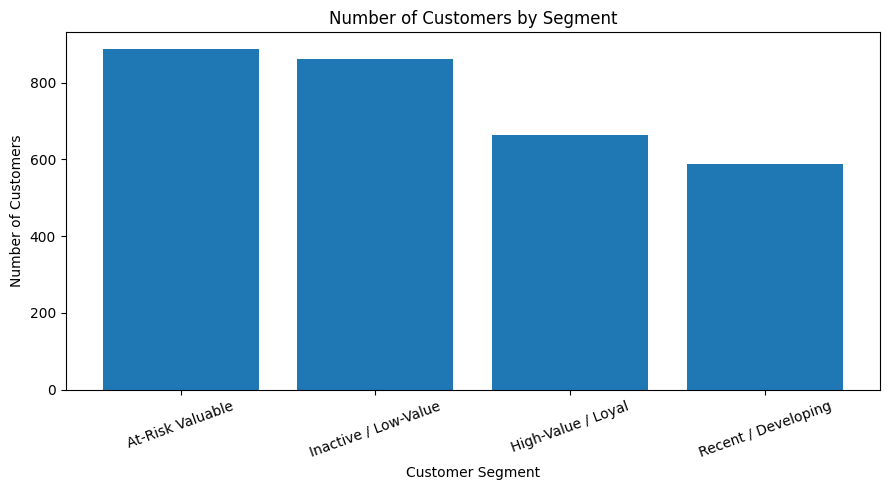

In [128]:
plt.figure(figsize=(9, 5))

plt.bar(
    segment_distribution["Segment"],
    segment_distribution["Customers"]
)

plt.title("Number of Customers by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

Elbow → Silhouette → Why K=4? → Final Cluster Profile → Business Interpretation

## 5.3 Customer Retention


In [129]:
# Confusion Matrix ของ Final Balanced Logistic Regression
final_cm = confusion_matrix(
    y_test,
    y_pred_balanced
)

final_cm_df = pd.DataFrame(
    final_cm,
    index=["Actual Non-Churn", "Actual Churn"],
    columns=["Predicted Non-Churn", "Predicted Churn"]
)

final_cm_df

,Predicted Non-Churn,Predicted Churn
Actual Non-Churn,327,100
Actual Churn,41,108


### Warning Signs


In [130]:
coefficients = pd.DataFrame({
    "Feature": feature_columns,
    "Coefficient": logistic_balanced.coef_[0]
})

coefficients["Abs_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "Abs_Coefficient",
    ascending=False
)

coefficients

,Feature,Coefficient,Abs_Coefficient
2,monetary,-1.899524,1.899524
8,transactions_180d,-1.019221,1.019221
3,avg_basket_value,0.941009,0.941009
5,total_discount,0.904497,0.904497
0,recency,0.647359,0.647359
7,transactions_90d,-0.553275,0.553275
1,frequency,0.467711,0.467711
9,transactions_365d,0.376588,0.376588
6,transactions_30d,-0.370623,0.370623
4,avg_units,-0.317394,0.317394


### Confusion Matrix / Correlation Matrix


In [131]:
correlation_matrix = X.corr()

correlation_matrix.round(2)

,recency,frequency,monetary,avg_basket_value,avg_units,total_discount,transactions_30d,transactions_90d,transactions_180d,transactions_365d
recency,1.00,-0.30,-0.26,-0.25,-0.19,-0.15,-0.48,-0.47,-0.42,-0.34
frequency,-0.30,1.00,0.94,0.72,0.62,0.59,0.61,0.81,0.90,0.96
monetary,-0.26,0.94,1.00,0.81,0.69,0.58,0.61,0.79,0.87,0.91
avg_basket_value,-0.25,0.72,0.81,1.00,0.89,0.50,0.51,0.65,0.71,0.73
avg_units,-0.19,0.62,0.69,0.89,1.00,0.48,0.42,0.55,0.60,0.64
total_discount,-0.15,0.59,0.58,0.50,0.48,1.00,0.35,0.47,0.52,0.57
transactions_30d,-0.48,0.61,0.61,0.51,0.42,0.35,1.00,0.78,0.71,0.65
transactions_90d,-0.47,0.81,0.79,0.65,0.55,0.47,0.78,1.00,0.92,0.86
transactions_180d,-0.42,0.90,0.87,0.71,0.60,0.52,0.71,0.92,1.00,0.96
transactions_365d,-0.34,0.96,0.91,0.73,0.64,0.57,0.65,0.86,0.96,1.00


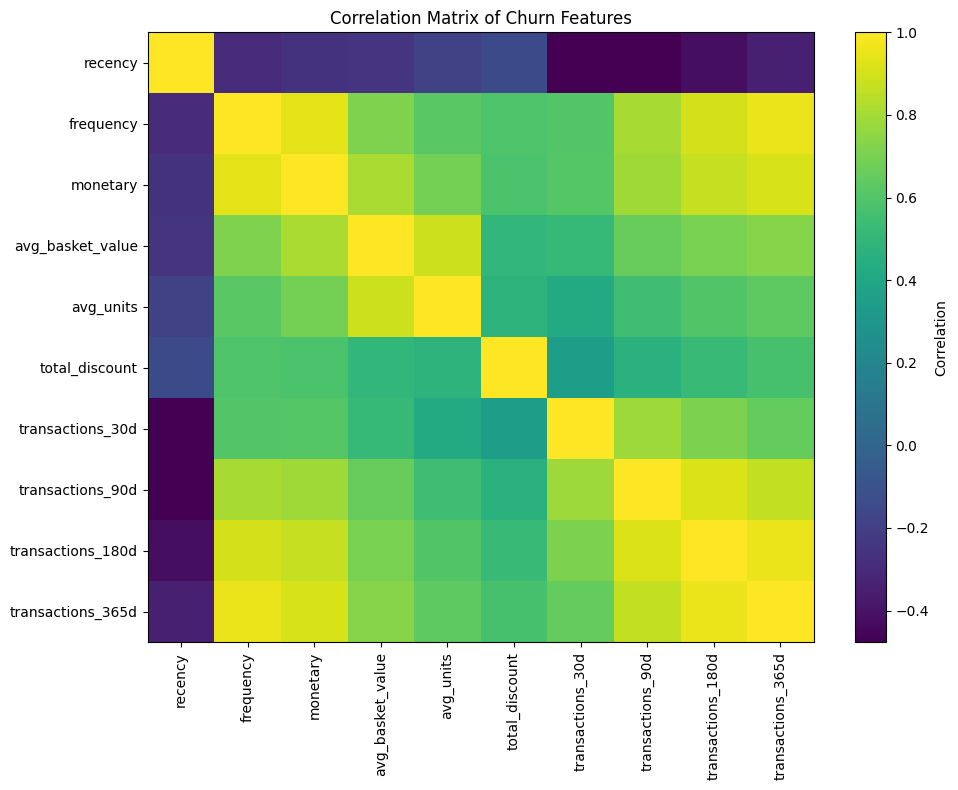

In [132]:
plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix of Churn Features")
plt.tight_layout()
plt.show()

### Model Comparison


In [133]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Balanced Logistic Regression",
        "Balanced Logistic + Purchase Trend"
    ],
    "Accuracy": [
        0.8090,
        0.7552,
        final_metrics["Accuracy"]
    ],
    "Precision": [
        0.7294,
        0.5192,
        final_metrics["Precision"]
    ],
    "Recall": [
        0.4161,
        0.7248,
        final_metrics["Recall"]
    ],
    "F1-Score": [
        0.5299,
        0.6050,
        final_metrics["F1-Score"]
    ],
    "ROC-AUC": [
        0.8369,
        0.8375,
        final_metrics["ROC-AUC"]
    ],
    "PR-AUC": [
        0.6753,
        0.6676,
        final_metrics["PR-AUC"]
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline Logistic Regression,0.8090,0.7294,0.4161,0.5299,0.8369,0.6753
1,Balanced Logistic Regression,0.7552,0.5192,0.7248,0.6050,0.8375,0.6676
2,Balanced Logistic + Purchase Trend,0.7569,0.5217,0.7248,0.6067,0.8377,0.6675


### Final Model Warning Signs


In [134]:
final_coefficients = pd.DataFrame({
    "Feature": final_feature_columns,
    "Coefficient": logistic_final.coef_[0]
})

final_coefficients["Abs_Coefficient"] = (
    final_coefficients["Coefficient"].abs()
)

final_coefficients = final_coefficients.sort_values(
    "Abs_Coefficient",
    ascending=False
)

final_coefficients

,Feature,Coefficient,Abs_Coefficient
2,monetary,-1.904738,1.904738
7,transactions_90d,-1.580367,1.580367
3,avg_basket_value,0.937213,0.937213
5,total_discount,0.904461,0.904461
0,recency,0.653462,0.653462
1,frequency,0.464519,0.464519
9,purchase_trend_90d,0.399411,0.399411
6,transactions_30d,-0.372523,0.372523
8,transactions_365d,0.345086,0.345086
4,avg_units,-0.314901,0.314901


### Warning Signs Visualization


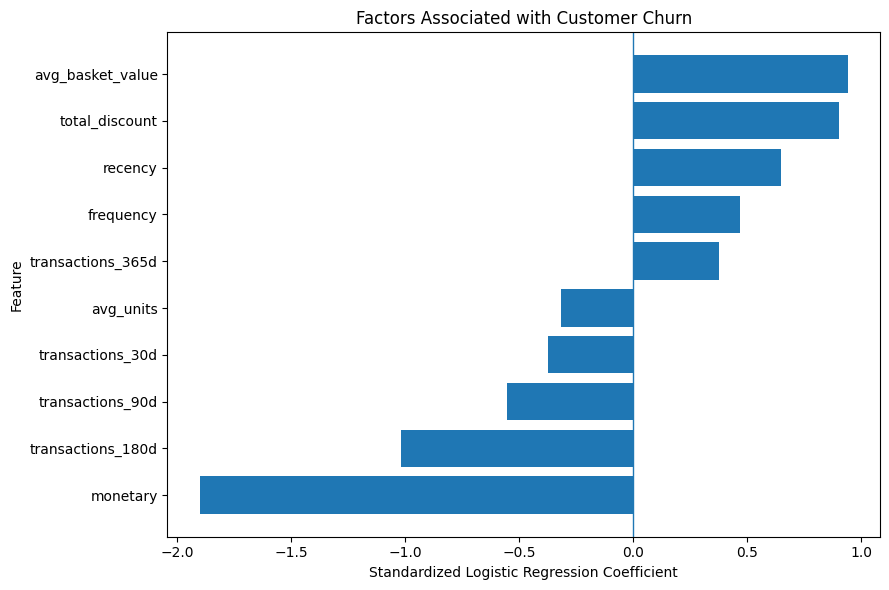

In [135]:
coef_plot = pd.DataFrame({
    "Feature": feature_columns,
    "Coefficient": logistic_balanced.coef_[0]
}).sort_values(
    "Coefficient"
)

plt.figure(figsize=(9, 6))

plt.barh(
    coef_plot["Feature"],
    coef_plot["Coefficient"]
)

plt.axvline(
    x=0,
    linewidth=1
)

plt.xlabel("Standardized Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Factors Associated with Customer Churn")

plt.tight_layout()
plt.show()

### Metrics: Precision / Recall / F1 / ROC-AUC / PR-AUC

> ได้ทดลอง Logistic Regression จำนวน 3 รูปแบบ ได้แก่ Baseline Logistic Regression, Balanced Logistic Regression และ Balanced Logistic Regression ที่เพิ่ม Purchase Trend Feature

Baseline Logistic Regression ให้ Accuracy สูงที่สุดที่ 80.90% แต่มี Recall สำหรับกลุ่ม Churn เพียง 41.61% หมายความว่าโมเดลตรวจพบลูกค้า Churn ได้ไม่ถึงครึ่งหนึ่งของลูกค้าที่ Churn จริง

เมื่อกำหนด `class_weight="balanced"` พบว่า Recall เพิ่มขึ้นเป็น 72.48% และ F1-Score เพิ่มขึ้นจาก 0.5299 เป็น 0.6050 แม้ Accuracy และ Precision จะลดลง โดยจำนวนลูกค้า Churn ที่โมเดลตรวจไม่พบ (False Negative) ลดลงจาก 87 คนเหลือ 41 คน

นอกจากนี้ได้ทดลอง Feature Engineering โดยสร้าง Purchase Trend เพื่อเปรียบเทียบกิจกรรมการซื้อในช่วง 90 วันล่าสุดกับช่วง 90 วันก่อนหน้า ผลพบว่า Recall ยังคงอยู่ที่ 72.48% ขณะที่ F1-Score เพิ่มขึ้นเพียงเล็กน้อยจาก 0.6050 เป็น 0.6067 และ ROC-AUC เพิ่มจาก 0.8375 เป็น 0.8377 จึงไม่พบการปรับปรุงประสิทธิภาพที่ชัดเจนจาก Feature ดังกล่าว

> ดังนั้นจึงเลือก **Balanced Logistic Regression** เป็น Final Model เนื่องจากมีโครงสร้างที่เรียบง่าย สามารถอธิบายผลได้ และสามารถตรวจพบลูกค้าที่ Churn ได้มากกว่า Baseline อย่างชัดเจน ซึ่งสอดคล้องกับวัตถุประสงค์ของ Customer Retention ที่ต้องการระบุลูกค้าที่มีความเสี่ยงเพื่อดำเนินมาตรการรักษาลูกค้าล่วงหน้า


### Warning Signs Summary

จาก Coefficient ของ Balanced Logistic Regression พบพฤติกรรมที่สามารถใช้เป็นสัญญาณประกอบการประเมินความเสี่ยงของ Customer Churn ได้ดังนี้

1. **ระยะเวลาจากการซื้อครั้งล่าสุดเพิ่มขึ้น (High Recency)**  
   Recency มี Coefficient เป็นบวก แสดงว่าลูกค้าที่ไม่ได้กลับมาซื้อสินค้าเป็นระยะเวลานานมีแนวโน้มถูกโมเดลจัดว่ามีความเสี่ยง Churn สูงขึ้น

2. **กิจกรรมการซื้อในช่วงล่าสุดต่ำลง**  
   จำนวน Transaction ในช่วง 30, 90 และ 180 วันมี Coefficient เป็นลบ โดยเฉพาะจำนวน Transaction ในช่วง 180 วัน ดังนั้นลูกค้าที่มีกิจกรรมการซื้อในช่วงล่าสุดต่ำเป็นกลุ่มที่ควรได้รับการติดตาม

3. **มูลค่าการซื้อสะสมต่ำ**  
   Monetary มี Coefficient เป็นลบและมีขนาดสัมบูรณ์สูงที่สุดในโมเดล แสดงว่ามูลค่าการซื้อสะสมที่สูงสัมพันธ์กับความเสี่ยง Churn ที่ต่ำลง เมื่อพิจารณาร่วมกับ Feature อื่นในโมเดล

4. **จำนวนสินค้าต่อ Transaction ต่ำ**  
   Average Units มี Coefficient เป็นลบ แสดงว่าลูกค้าที่ซื้อสินค้าจำนวนมากต่อ Transaction มีแนวโน้มถูกจัดว่ามีความเสี่ยงต่ำกว่า

อย่างไรก็ตาม Feature ที่เกี่ยวข้องกับ Frequency และจำนวน Transaction ในช่วงเวลาต่าง ๆ มี Correlation กันค่อนข้างสูง จึงควรตีความ Coefficient ของแต่ละ Featureร่วมกับพฤติกรรมโดยรวม และไม่ควรตีความเป็นความสัมพันธ์เชิงเหตุและผลโดยตรง


### Final Model Selection and Business Recommendations

จากผลการทำนาย Customer Churn ธุรกิจสามารถนำโมเดลไปใช้สร้าง Customer Retention Campaign โดยคำนวณ Churn Probability ของลูกค้าเป็นระยะ และจัดลำดับลูกค้าตามระดับความเสี่ยง

ลูกค้าที่มี Recency สูง มีกิจกรรมการซื้อในช่วง 30–180 วันต่ำ และมีมูลค่าการซื้อสะสมต่ำ ควรได้รับการติดตามเป็นกลุ่มเสี่ยง โดยสามารถใช้มาตรการ เช่น Personalized Reminder, Product Recommendation, Win-back Campaign หรือ Promotion เพื่อกระตุ้นให้กลับมาซื้อสินค้า

สำหรับลูกค้าที่มีความเสี่ยงสูงแต่เคยสร้างมูลค่าให้ธุรกิจสูง สามารถให้ความสำคัญเป็นพิเศษ เนื่องจากการรักษาลูกค้ากลุ่มดังกล่าวอาจมีมูลค่าทางธุรกิจมากกว่าการใช้ Promotion แบบเดียวกันกับลูกค้าทุกคน

เนื่องจาก Final Model มี Recall 72.48% แต่ Precision 51.92% การนำไปใช้งานจริงควรพิจารณาต้นทุนของ Retention Campaign ร่วมด้วย หาก Campaign มีต้นทุนต่ำ ธุรกิจสามารถยอมรับ False Positive บางส่วนเพื่อเพิ่มโอกาสในการตรวจพบลูกค้าที่มีความเสี่ยง Churn ได้มากขึ้น


## 5.4 Overall Evaluation



ผลการวิเคราะห์ทั้ง 3 ส่วนสามารถตอบ Business Problems ที่กำหนดไว้ได้ โดยแต่ละวิธีให้ผลลัพธ์ที่สามารถนำไปสนับสนุนการตัดสินใจทางธุรกิจได้ในมุมที่แตกต่างกัน

1. **Increase Basket Size:**  
Association Rule Mining สามารถค้นหาสินค้าที่มีแนวโน้มถูกซื้อร่วมกันได้ โดย Apriori และ FP-Growth ให้ Frequent Itemsets และ Association Rules เหมือนกันภายใต้เงื่อนไขเดียวกัน แต่ Apriori ใช้เวลาในการประมวลผลน้อยกว่าสำหรับ Dataset นี้ ผลลัพธ์ที่ได้สามารถนำไปใช้เป็นแนวทางสำหรับ Cross-selling, Bundle Promotion และ Product Recommendation

2. **Customer Segmentation:**  
RFM ร่วมกับ K-Means สามารถแบ่งลูกค้าออกเป็น 4 กลุ่มที่มีพฤติกรรมแตกต่างกัน ได้แก่ High-Value / Loyal, Recent / Developing, At-Risk Valuable และ Inactive / Low-Value โดยการเลือก K=4 พิจารณาจาก Elbow Method, Silhouette Score และความสามารถในการตีความเชิงธุรกิจ ผลลัพธ์สามารถนำไปใช้กำหนด Marketing Strategy ที่เหมาะสมกับลูกค้าแต่ละกลุ่ม

3. **Customer Retention:**  
Balanced Logistic Regression ถูกเลือกเป็น Final Model เนื่องจากสามารถเพิ่ม Recall ของกลุ่ม Churn จาก 41.61% เป็น 72.48% และลดจำนวน False Negative จาก 87 คนเหลือ 41 คน แม้ Precision และ Accuracy จะลดลงเมื่อเทียบกับ Baseline Model แต่เหมาะสมกับวัตถุประสงค์ด้าน Customer Retention ที่ต้องการตรวจพบลูกค้าที่มีความเสี่ยงให้ได้มากขึ้น

โดยรวม ผลลัพธ์จากทั้ง 3 ส่วนสามารถเชื่อมโยงกันเพื่อสนับสนุนกลยุทธ์ทางธุรกิจได้ ตั้งแต่การเพิ่มมูลค่าต่อ Transaction การทำ Targeted Marketing ไปจนถึงการรักษาลูกค้าที่มีความเสี่ยง Churn และสามารถนำผลลัพธ์เหล่านี้ไปประยุกต์ใช้ในขั้นตอน Deployment ต่อไป

# 6. Deployment


## 6.1 Association Rule Deployment

Cross-selling / bundle recommendations are created from the selected association rules.

Code: `deployment_rules`

Output: Product -> Recommended Product


In [136]:
deployment_rules = pair_rules[
    (pair_rules["lift"] > 1)
].copy()

deployment_rules["antecedent"] = deployment_rules["antecedents"].apply(
    lambda x: ", ".join(list(x))
)
deployment_rules["consequent"] = deployment_rules["consequents"].apply(
    lambda x: ", ".join(list(x))
)

deployment_rules = deployment_rules[
    [
        "antecedent",
        "consequent",
        "support",
        "confidence",
        "lift"
    ]
].sort_values(
    ["lift", "confidence", "support"],
    ascending=False
)

deployment_rules.head(10)

,antecedent,consequent,support,confidence,lift
80,Coffee Creamer,Coffee Filter Paper,0.030129,0.652117,11.689890
81,Coffee Filter Paper,Coffee Creamer,0.030129,0.540092,11.689890
69,Pet Shampoo,Dog Treats,0.012540,0.497294,11.646499
56,Baby Lotion,Baby Wipes,0.021425,0.660280,10.897270
57,Baby Wipes,Baby Lotion,0.021425,0.353604,10.897270
55,Baby Lotion,Diapers Pack,0.021804,0.671963,10.097046
54,Diapers Pack,Baby Lotion,0.021804,0.327637,10.097046
75,Dog Treats,Dog Food 3kg,0.023366,0.547230,9.698959
74,Dog Food 3kg,Dog Treats,0.023366,0.414136,9.698959
77,Coffee Filter Paper,Coffee Beans 250g,0.040136,0.719489,9.412874


## 6.2 Customer Segmentation Deployment

Customer segments are mapped to practical marketing or CRM actions.

Code: `segment_actions`, `customer_segment_deployment`

Output: Customer -> Segment -> Recommended Action


In [137]:
segment_actions = {
    "High-Value / Loyal": "VIP Benefits / Loyalty Program / Personalized Offers",
    "Recent / Developing": "Second-purchase Promotion / Cross-selling",
    "At-Risk Valuable": "Win-back Campaign / Personalized Reminder",
    "Inactive / Low-Value": "Low-cost Re-engagement Campaign"
}

customer_segment_deployment = rfm[
    ["customer_id", "Recency", "Frequency", "Monetary", "Segment"]
].copy()

customer_segment_deployment["Recommended_Action"] = (
    customer_segment_deployment["Segment"].map(segment_actions)
)

customer_segment_deployment.head(10)

,customer_id,Recency,Frequency,Monetary,Segment,Recommended_Action
0,C10001,180,7,7401.33,Inactive / Low-Value,Low-cost Re-engagement Campaign
1,C10002,4,8,3282.67,Recent / Developing,Second-purchase Promotion / Cross-selling
2,C10003,154,4,3110.29,Inactive / Low-Value,Low-cost Re-engagement Campaign
3,C10004,10,6,2507.13,Recent / Developing,Second-purchase Promotion / Cross-selling
4,C10005,4,12,6843.47,Recent / Developing,Second-purchase Promotion / Cross-selling
5,C10006,81,12,7232.42,Inactive / Low-Value,Low-cost Re-engagement Campaign
6,C10007,1,5,9399.24,Recent / Developing,Second-purchase Promotion / Cross-selling
7,C10008,58,2,3039.52,Inactive / Low-Value,Low-cost Re-engagement Campaign
8,C10009,34,4,1905.10,Inactive / Low-Value,Low-cost Re-engagement Campaign
9,C10010,119,15,11237.07,At-Risk Valuable,Win-back Campaign / Personalized Reminder


## 6.3 Customer Retention Deployment

Risk scoring converts churn probability into an operational retention action.

Code: `churn_probability`, `risk_level`, `recommended_action`

Output: Customer -> Churn Probability -> Risk -> Action


In [138]:
churn_deployment = churn_dataset[
    ["customer_id"] + feature_columns
].copy()

X_deployment = churn_deployment[feature_columns]

X_deployment_scaled = churn_scaler.transform(X_deployment)

churn_deployment["churn_probability"] = (
    logistic_balanced.predict_proba(X_deployment_scaled)[:, 1]
)

churn_deployment["risk_level"] = pd.cut(
    churn_deployment["churn_probability"],
    bins=[0, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

churn_deployment = churn_deployment.sort_values(
    "churn_probability",
    ascending=False
)

churn_deployment[
    [
        "customer_id",
        "recency",
        "frequency",
        "monetary",
        "churn_probability",
        "risk_level"
    ]
].head(10)

,customer_id,recency,frequency,monetary,churn_probability,risk_level
1884,C11964,478,7,8642.65,0.997589,High
2443,C12546,418,14,23013.79,0.997361,High
805,C10835,390,6,11309.37,0.996084,High
1360,C11410,435,3,7206.66,0.995995,High
753,C10782,291,5,10775.86,0.995403,High
1619,C11681,304,4,8550.94,0.994867,High
1713,C11779,403,3,3833.20,0.993428,High
188,C10199,335,7,14643.18,0.993033,High
1104,C11148,344,9,12851.33,0.991997,High
1543,C11602,380,3,2337.54,0.991096,High


### Business Action

In [139]:
retention_actions = {
    "High": "Priority Win-back Campaign",
    "Medium": "Reminder / Personalized Offer",
    "Low": "Regular Engagement"
}

churn_deployment["recommended_action"] = (
    churn_deployment["risk_level"]
    .astype(str)
    .map(retention_actions)
)

churn_deployment[
    [
        "customer_id",
        "churn_probability",
        "risk_level",
        "recommended_action"
    ]
].head(10)

,customer_id,churn_probability,risk_level,recommended_action
1884,C11964,0.997589,High,Priority Win-back Campaign
2443,C12546,0.997361,High,Priority Win-back Campaign
805,C10835,0.996084,High,Priority Win-back Campaign
1360,C11410,0.995995,High,Priority Win-back Campaign
753,C10782,0.995403,High,Priority Win-back Campaign
1619,C11681,0.994867,High,Priority Win-back Campaign
1713,C11779,0.993428,High,Priority Win-back Campaign
188,C10199,0.993033,High,Priority Win-back Campaign
1104,C11148,0.991997,High,Priority Win-back Campaign
1543,C11602,0.991096,High,Priority Win-back Campaign


## 6.4 Proposed Deployment Workflow

New Data
↓
Data Preparation
↓
Models
↓
Business Actions
↓
Monitoring


## 6.5 Monitoring & Maintenance



หลังจากนำผลการวิเคราะห์ไปประยุกต์ใช้ ควรมีการติดตามทั้งประสิทธิภาพของโมเดลและผลลัพธ์ทางธุรกิจอย่างสม่ำเสมอ เพื่อให้ผลการวิเคราะห์ยังคงเหมาะสมกับพฤติกรรมของลูกค้าที่อาจเปลี่ยนแปลงไปตามเวลา

**Association Rules**
- คำนวณ Frequent Itemsets และ Association Rules ใหม่เป็นระยะเมื่อมีข้อมูล Transaction ใหม่เพิ่มขึ้น
- ติดตามตัวชี้วัดทางธุรกิจ เช่น Average Basket Size, Average Order Value, Cross-sell Conversion Rate และผลลัพธ์ของ Bundle Promotion
- ตรวจสอบว่าความสัมพันธ์ระหว่างสินค้าที่เคยพบยังคงมีความสม่ำเสมอเมื่อเวลาผ่านไปหรือไม่

**Customer Segmentation**
- คำนวณค่า RFM และจัดกลุ่มลูกค้าใหม่เป็นระยะโดยใช้ข้อมูล Transaction ล่าสุด
- ติดตามจำนวนลูกค้าในแต่ละ Segment รวมถึงการย้ายระหว่าง Segment ของลูกค้า
- ประเมิน Campaign Response Rate และรายได้ที่เกิดจากลูกค้าในแต่ละ Segment เพื่อวัดประสิทธิผลของกลยุทธ์ที่นำไปใช้

**Customer Retention**
- ติดตามประสิทธิภาพของโมเดลด้วย Precision, Recall, F1-Score, ROC-AUC และ PR-AUC
- ติดตามผลลัพธ์ทางธุรกิจ เช่น Churn Rate, Retention Rate และ Win-back Campaign Response Rate
- พิจารณา Retrain โมเดลเมื่อมีข้อมูลใหม่เพียงพอ หรือเมื่อพบว่าประสิทธิภาพของโมเดลลดลง

การติดตามผลอย่างต่อเนื่องจะช่วยให้โมเดลและกลยุทธ์ทางธุรกิจสามารถปรับตัวให้สอดคล้องกับพฤติกรรมการซื้อของลูกค้าที่เปลี่ยนแปลงไปตามเวลา

## 6.6 Limitations & Future Improvement



แม้ว่าผลการวิเคราะห์จะสามารถนำไปใช้ตอบ Business Problems ทั้ง 3 ข้อได้ แต่ยังมีข้อจำกัดที่ควรพิจารณาก่อนนำผลลัพธ์ไปใช้งานจริง

**Association Rules**
- Association Rules แสดงถึงความสัมพันธ์ของสินค้าที่มักถูกซื้อร่วมกัน แต่ไม่ได้หมายความว่าสินค้าหนึ่งเป็นสาเหตุให้อีกสินค้าหนึ่งถูกซื้อ
- ความสัมพันธ์ของสินค้าอาจเปลี่ยนแปลงตามเวลา ฤดูกาล Promotion หรือพฤติกรรมของลูกค้า
- Promotion ที่ออกแบบจาก Association Rules ควรได้รับการทดลองและประเมินผลจริง เช่น การทำ A/B Testing ก่อนนำไปใช้ในวงกว้าง

**Customer Segmentation**
- K-Means เป็น Unsupervised Learning ดังนั้น Cluster ที่ได้จึงไม่มี Ground Truth Label สำหรับใช้ตรวจสอบความถูกต้องโดยตรง
- ชื่อของแต่ละ Segment ถูกกำหนดภายหลังจากการวิเคราะห์ลักษณะของ RFM Profile เพื่อให้สามารถตีความในเชิงธุรกิจได้
- พฤติกรรมของลูกค้าสามารถเปลี่ยนแปลงได้ตามเวลา ทำให้ลูกค้าสามารถย้ายจาก Segment หนึ่งไปยังอีก Segment หนึ่งได้

**Customer Retention**
- Final Balanced Logistic Regression มี Recall สำหรับกลุ่ม Churn เท่ากับ 72.48% และ Precision เท่ากับ 51.92% จึงยังมีลูกค้าบางส่วนที่ถูกระบุว่ามีความเสี่ยงสูง แต่ไม่ได้ Churn จริง
- Feature ที่เกี่ยวข้องกับ Frequency และจำนวน Transaction ในช่วงเวลาต่าง ๆ มี Correlation กันค่อนข้างสูง ซึ่งอาจส่งผลต่อการตีความ Coefficient ของ Logistic Regression
- Coefficient ของโมเดลจึงควรตีความในลักษณะของความสัมพันธ์เชิงการทำนาย (Predictive Association) และไม่ควรสรุปว่าเป็นความสัมพันธ์เชิงเหตุและผลโดยตรง

**แนวทางการพัฒนาในอนาคต**

- ในอนาคตสามารถทดลอง Classification Algorithm อื่นเพิ่มเติม รวมถึงสร้าง Behavioral Features ใหม่ เพื่อศึกษาว่าสามารถเพิ่มประสิทธิภาพในการตรวจจับลูกค้าที่มีความเสี่ยง Churn ได้หรือไม่

- นอกจากนี้สามารถปรับ Churn Probability Threshold ให้เหมาะสมกับต้นทุนของ Retention Campaign และมูลค่าของลูกค้า รวมถึงประเมินผลลัพธ์จาก Promotion, Product Recommendation และ Retention Campaign ที่เกิดขึ้นจริง เพื่อวัดว่าผลการวิเคราะห์สามารถสร้างผลลัพธ์ทางธุรกิจได้มากน้อยเพียงใด

- โมเดลและผลการวิเคราะห์ควรได้รับการประเมินและปรับปรุงเป็นระยะด้วยข้อมูล Transaction ใหม่ เพื่อให้สามารถสะท้อนพฤติกรรมของลูกค้าในปัจจุบันได้อย่างเหมาะสม